# Credit Default Prediction: Gradient Boosting Ensemble & Anomaly Detection
### Technical Portfolio | GASSS JUARA — DSC LOGIKA UI 2026

**Engineering focus:** time-aware credit feature engineering, 5-fold OOF validation, LightGBM/CatBoost/XGBoost training, weighted ensemble, and anomaly-aware experiments. **Metric:** Kolmogorov–Smirnov statistic (KS).

**Documented results (original competition run):** 5-fold aligned OOF KS **0.512201**, AUC **0.837744**, public KS **0.55163**, private KS **0.53271**. The numbers are historical observations, **not freshly reproduced by this notebook**.

This notebook includes **real training and preprocessing code excerpts from the 229-cell project notebook**, explicitly marked as archived and disabled by default, alongside an executable environment check, metric demonstrations, and leaderboard analysis. It **does not claim to reproduce the winning prediction without the original competition data, saved features, training splits, and checkpoints**.

### Project Overview

This project was developed by Team GASSS JUARA for the DSC LOGIKA UI 2026 Data Science Competition.

We built a credit default prediction system using LightGBM, CatBoost, XGBoost, and weighted ensemble learning.

**Key Results:**
- Public KS: **0.55163**
- Private KS: **0.53271**
- Out-of-Fold KS: **0.512201**
- Out-of-Fold AUC: **0.837744**

We also explored anomaly detection techniques, including FastABOD and One-Class SVM, to investigate whether anomaly-aware training could improve model performance.

The notebook documents our feature engineering, model development, cross-validation, ensemble strategy, and lessons learned about generalization.

## 1. Environment, reproducibility & usage

**Quick mode (default):** `Run All` on Kaggle/Colab/local Jupyter runs the self-contained diagnostics and charts; the historical pipeline snippets remain disabled intentionally.

**Research mode:** inspect the historical source cells to understand our actual training workflow. The original 229-cell notebook must be used with the original competition files and checkpoint directory for end-to-end reconstruction. Do not turn the historical sections on without restoring their dependencies and original execution order.

The competition's data-access and publishing rules should be respected before sharing source data or model weights.

In [1]:
from pathlib import Path
import sys, importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RUN_HISTORICAL_PIPELINE = False  # Archived cells below are illustrative real project code.
COMPETITION_ROOT = Path('/kaggle/input') if Path('/kaggle/input').exists() else Path.cwd()
print('Python:', sys.version.split()[0], '| pandas:', pd.__version__, '| numpy:', np.__version__)
print('Data root:', COMPETITION_ROOT)
print('Historical model pipeline enabled:', RUN_HISTORICAL_PIPELINE)
for package in ['lightgbm', 'catboost', 'xgboost', 'sklearn', 'pyarrow']:
    print(f'{package}:', 'installed' if importlib.util.find_spec(package) else 'not installed')

Python: 3.13.15 | pandas: 2.3.3 | numpy: 2.1.3
Data root: /kaggle/input
Historical model pipeline enabled: False
lightgbm: installed
catboost: installed
xgboost: installed
sklearn: installed
pyarrow: installed


## 2. Problem framing & KS evaluation
A credit risk model must assign higher default probabilities to applicants more likely to default. KS is the maximum separation of the empirical distributions of predicted risk among default and non-default borrowers. **OOF results** measure internal validation; **public/private scores** are separately computed on Kaggle's hidden test partitions.

In [2]:
from sklearn.metrics import roc_curve, roc_auc_score

def ks_statistic(y_true, y_score):
    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score, dtype=float)
    if y_true.shape != y_score.shape:
        raise ValueError('Label/score lengths differ')
    if not np.isfinite(y_score).all():
        raise ValueError('Predictions contain non-finite values')
    fpr, tpr, _ = roc_curve(y_true, y_score)
    return float(np.max(tpr - fpr))

# Deterministic smoke test only — synthetic data, NOT competition validation.
_rng = np.random.default_rng(42)
_demo_y = _rng.binomial(1, .14, size=3000)
_demo_score = np.clip(_rng.normal(.12 + .42 * _demo_y, .18), 0, 1)
print('Synthetic KS:', round(ks_statistic(_demo_y, _demo_score), 4))
print('Synthetic AUC:', round(roc_auc_score(_demo_y, _demo_score), 4))

Synthetic KS: 0.7884
Synthetic AUC: 0.9532


## 3. Competition data inspection & temporal feature engineering

Our original feature engineering used the application/decision cutoffs to avoid incorporating records from the future. Training assembled applicant-level aggregations from the provided auxiliary tables (e.g. repayment history, previous applications, transactions). **The following code is preserved from actual development**, but the original source uses paths under `/content/dsc_logika` and Google Drive, so it is *disabled by default* in this portable notebook.

#### Target rate and training data — original source cell 11


*Preserved from `dsc_logika_ui.ipynb`. Requires original project state and data. The cell is safely disabled in quick mode.*

In [ ]:
if RUN_HISTORICAL_PIPELINE:
    train = pd.read_csv(
        DATA_DIR / "train_applications.csv"
    )
    
    print("Jumlah data training:", len(train))
    
    print("\nDistribusi target:")
    print(train["target"].value_counts())
    
    print("\nPersentase target:")
    print(
        train["target"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )
    
    print("\nApplication ID unik:",
          train["application_id"].nunique())
    
    print("Customer ID unik:",
          train["customer_id"].nunique())


#### Application-level timeline — original source cell 13


*Preserved from `dsc_logika_ui.ipynb`. Requires original project state and data. The cell is safely disabled in quick mode.*

In [ ]:
if RUN_HISTORICAL_PIPELINE:
    import pandas as pd
    from pathlib import Path
    
    DATA_DIR = Path("/content/dsc_logika")
    
    train = pd.read_csv(
        DATA_DIR / "train_applications.csv",
        usecols=["application_id", "customer_id", "decision_datetime"],
        parse_dates=["decision_datetime"]
    )
    
    test = pd.read_csv(
        DATA_DIR / "test_applications.csv",
        usecols=["application_id", "customer_id", "decision_datetime"],
        parse_dates=["decision_datetime"]
    )
    
    previous = pd.read_csv(
        DATA_DIR / "previous_applications.csv",
        usecols=["application_id", "customer_id", "decision_datetime"],
        parse_dates=["decision_datetime"]
    )
    
    bureau = pd.read_csv(
        DATA_DIR / "bureau_observations.csv",
        usecols=[
            "application_id",
            "customer_id",
            "report_datetime",
            "available_datetime"
        ],
        parse_dates=["report_datetime", "available_datetime"]
    )
    
    selected = pd.concat([train, test], ignore_index=True)
    
    selected_ids = set(selected["application_id"])
    previous_ids = set(previous["application_id"])
    
    bureau["is_selected"] = bureau["application_id"].isin(selected_ids)
    bureau["is_previous"] = bureau["application_id"].isin(previous_ids)
    
    print("=== BUREAU APPLICATION LINKAGE ===")
    print("Total bureau rows:", len(bureau))
    
    print(
        "Selected application rows:",
        bureau["is_selected"].sum()
    )
    
    print(
        "Previous application rows:",
        bureau["is_previous"].sum()
    )
    
    print(
        "Neither selected nor previous:",
        (~bureau["is_selected"] & ~bureau["is_previous"]).sum()
    )
    
    print("\n=== TIME AVAILABILITY ===")
    
    selected_decision = selected.set_index(
        "application_id"
    )["decision_datetime"]
    
    bureau["selected_decision_datetime"] = (
        bureau["application_id"].map(selected_decision)
    )
    
    selected_bureau = bureau[
        bureau["selected_decision_datetime"].notna()
    ].copy()
    
    selected_bureau["available_before_decision"] = (
        selected_bureau["available_datetime"]
        <= selected_bureau["selected_decision_datetime"]
    )
    
    print(
        "Available before selected decision:",
        selected_bureau["available_before_decision"].mean()
    )
    
    print("\n=== SELECTED APPLICATION DATE RANGE ===")
    print(selected["decision_datetime"].min())
    print(selected["decision_datetime"].max())
    
    print("\n=== BUREAU DATE RANGE ===")
    print(bureau["available_datetime"].min())
    print(bureau["available_datetime"].max())


#### Time-cutoff selection — original source cell 14


*Preserved from `dsc_logika_ui.ipynb`. Requires original project state and data. The cell is safely disabled in quick mode.*

In [ ]:
if RUN_HISTORICAL_PIPELINE:
    import pandas as pd
    from pathlib import Path
    
    DATA_DIR = Path("/content/dsc_logika")
    
    selected = pd.concat([
        pd.read_csv(
            DATA_DIR / "train_applications.csv",
            usecols=["customer_id", "decision_datetime"]
        ),
        pd.read_csv(
            DATA_DIR / "test_applications.csv",
            usecols=["customer_id", "decision_datetime"]
        )
    ], ignore_index=True)
    
    selected["decision_datetime"] = pd.to_datetime(
        selected["decision_datetime"]
    )
    
    previous = pd.read_csv(
        DATA_DIR / "previous_applications.csv",
        usecols=[
            "loan_id",
            "customer_id",
            "decision_datetime"
        ]
    )
    
    previous["decision_datetime"] = pd.to_datetime(
        previous["decision_datetime"]
    )
    
    repayment = pd.read_csv(
        DATA_DIR / "repayment_history.csv",
        usecols=[
            "loan_id",
            "customer_id",
            "due_date",
            "last_payment_datetime",
            "days_past_due",
            "max_days_past_due"
        ]
    )
    
    repayment["due_date"] = pd.to_datetime(
        repayment["due_date"]
    )
    
    repayment["last_payment_datetime"] = pd.to_datetime(
        repayment["last_payment_datetime"]
    )
    
    # Memetakan waktu keputusan aplikasi terpilih
    decision_map = selected.set_index(
        "customer_id"
    )["decision_datetime"]
    
    repayment["selected_decision"] = (
        repayment["customer_id"].map(decision_map)
    )
    
    # Memetakan waktu keputusan pinjaman sebelumnya
    previous_loan_map = (
        previous.dropna(subset=["loan_id"])
        .drop_duplicates("loan_id")
        .set_index("loan_id")["decision_datetime"]
    )
    
    repayment["previous_decision"] = (
        repayment["loan_id"].map(previous_loan_map)
    )
    
    print("=== REPAYMENT TEMPORAL AUDIT ===")
    
    print("Total repayment rows:", len(repayment))
    
    print(
        "Due date setelah keputusan terpilih:",
        (repayment["due_date"] > repayment["selected_decision"]).sum()
    )
    
    print(
        "Last payment setelah atau sama dengan keputusan terpilih:",
        (
            repayment["last_payment_datetime"]
            >= repayment["selected_decision"]
        ).sum()
    )
    
    print(
        "Previous loan decision setelah atau sama dengan keputusan terpilih:",
        (
            repayment["previous_decision"]
            >= repayment["selected_decision"]
        ).sum()
    )
    
    print(
        "Missing selected decision:",
        repayment["selected_decision"].isna().sum()
    )
    
    print(
        "Missing previous loan mapping:",
        repayment["previous_decision"].isna().sum()
    )
    
    print("\n=== DPD DISTRIBUTION ===")
    print(
        repayment[
            ["days_past_due", "max_days_past_due"]
        ].describe()
    )


#### Repayment temporal features — original source cell 15


*Preserved from `dsc_logika_ui.ipynb`. Requires original project state and data. The cell is safely disabled in quick mode.*

In [ ]:
if RUN_HISTORICAL_PIPELINE:
    import pandas as pd
    import numpy as np
    
    repayment["days_since_due"] = (
        repayment["selected_decision"]
        - repayment["due_date"]
    ).dt.total_seconds() / 86400
    
    # Batas konservatif untuk DPD pada waktu keputusan:
    # DPD end-of-day bisa berbeda dari selisih waktu intrahari,
    # sehingga gunakan selisih tanggal kalender.
    repayment["calendar_days_since_due"] = (
        repayment["selected_decision"].dt.normalize()
        - repayment["due_date"].dt.normalize()
    ).dt.days
    
    print("=== DPD CONSISTENCY AUDIT ===")
    
    print(
        "Max DPD < current DPD:",
        (
            repayment["max_days_past_due"]
            < repayment["days_past_due"]
        ).sum()
    )
    
    print(
        "Current DPD melebihi umur sejak jatuh tempo:",
        (
            repayment["days_past_due"]
            > repayment["calendar_days_since_due"]
        ).sum()
    )
    
    print(
        "Max DPD melebihi umur sejak jatuh tempo:",
        (
            repayment["max_days_past_due"]
            > repayment["calendar_days_since_due"]
        ).sum()
    )
    
    print(
        "DPD negatif:",
        (
            (repayment["days_past_due"] < 0)
            | (repayment["max_days_past_due"] < 0)
        ).sum()
    )
    
    print("\n=== DPD THRESHOLD COUNTS ===")
    
    for threshold in [1, 7, 30, 60, 90]:
        count = (
            repayment["max_days_past_due"] >= threshold
        ).sum()
    
        print(
            f"Max DPD >= {threshold}: "
            f"{count:,} ({count / len(repayment):.2%})"
        )


#### Feature building from applications — original source cell 23


*Preserved from `dsc_logika_ui.ipynb`. Requires original project state and data. The cell is safely disabled in quick mode.*

In [ ]:
if RUN_HISTORICAL_PIPELINE:
    import pandas as pd
    import numpy as np
    from pathlib import Path
    
    DATA_DIR = Path("/content/dsc_logika")
    
    train = pd.read_csv(
        DATA_DIR / "train_applications.csv",
        parse_dates=["application_datetime", "decision_datetime"]
    )
    
    test = pd.read_csv(
        DATA_DIR / "test_applications.csv",
        parse_dates=["application_datetime", "decision_datetime"]
    )
    
    profiles = pd.read_csv(
        DATA_DIR / "customer_profiles.csv"
    )
    
    # Penanda sumber baris
    train["dataset_source"] = "train"
    test["dataset_source"] = "test"
    
    # Gabungkan train dan test untuk fitur deterministik
    base = pd.concat(
        [train, test],
        ignore_index=True
    )
    
    assert len(base) == 100000
    assert base["application_id"].is_unique
    assert base["customer_id"].is_unique
    
    # Gabungkan customer profiles
    features = base.merge(
        profiles,
        on="customer_id",
        how="left",
        validate="one_to_one"
    )
    
    assert len(features) == 100000
    
    # Rasio finansial
    income = features["declared_monthly_income"].replace(0, np.nan)
    amount = features["loan_amount"].replace(0, np.nan)
    
    features["installment_to_income"] = (
        features["proposed_monthly_installment"] / income
    )
    
    features["loan_to_income"] = features["loan_amount"] / income
    
    features["installment_to_loan"] = (
        features["proposed_monthly_installment"] / amount
    )
    
    features["income_per_household_member"] = (
        features["declared_monthly_income"]
        / (features["dependents"] + 1)
    )
    
    features["monthly_interest_rate"] = (
        features["annual_interest_rate"] / 12
    )
    
    features["decision_month"] = features["decision_datetime"].dt.month
    features["decision_dayofweek"] = features["decision_datetime"].dt.dayofweek
    features["decision_hour"] = features["decision_datetime"].dt.hour
    
    features["decision_delay_hours"] = (
        features["decision_datetime"] - features["application_datetime"]
    ).dt.total_seconds() / 3600
    
    print("Base feature matrix:", features.shape)
    print("Unique applications:", features["application_id"].nunique())
    print("Missing customer profiles:",
          features["age"].isna().sum())


#### Previous applications temporal join — original source cell 24


*Preserved from `dsc_logika_ui.ipynb`. Requires original project state and data. The cell is safely disabled in quick mode.*

In [ ]:
if RUN_HISTORICAL_PIPELINE:
    previous = pd.read_csv(
        DATA_DIR / "previous_applications.csv",
        parse_dates=["application_datetime", "decision_datetime"]
    )
    
    # Gabungkan cutoff keputusan aplikasi terpilih
    cutoffs = features[
        ["customer_id", "decision_datetime"]
    ].rename(
        columns={"decision_datetime": "selected_decision"}
    )
    
    prev = previous.merge(
        cutoffs,
        on="customer_id",
        how="inner",
        validate="many_to_one"
    )
    
    # Hanya aplikasi dan keputusan yang sudah diketahui
    prev = prev[
        (prev["application_datetime"] < prev["selected_decision"]) &
        (prev["decision_datetime"] < prev["selected_decision"])
    ].copy()
    
    prev["is_approved"] = (prev["decision"] == "approved").astype("int8")
    prev["is_rejected"] = (prev["decision"] == "rejected").astype("int8")
    prev["is_cancelled"] = (prev["decision"] == "cancelled").astype("int8")
    
    prev["days_since_previous"] = (
        prev["selected_decision"] - prev["decision_datetime"]
    ).dt.total_seconds() / 86400
    
    prev_features = prev.groupby("customer_id").agg(
        prev_application_count=("application_id", "count"),
        prev_approved_count=("is_approved", "sum"),
        prev_rejected_count=("is_rejected", "sum"),
        prev_cancelled_count=("is_cancelled", "sum"),
        prev_requested_mean=("requested_amount", "mean"),
        prev_requested_max=("requested_amount", "max"),
        prev_approved_amount_mean=("approved_amount", "mean"),
        prev_days_since_last=("days_since_previous", "min"),
        prev_days_since_first=("days_since_previous", "max"),
        prev_loan_count=("loan_id", "nunique")
    ).reset_index()
    
    prev_features["prev_approval_rate"] = (
        prev_features["prev_approved_count"]
        / prev_features["prev_application_count"]
    )
    
    prev_features["prev_rejection_rate"] = (
        prev_features["prev_rejected_count"]
        / prev_features["prev_application_count"]
    )
    
    features = features.merge(
        prev_features,
        on="customer_id",
        how="left",
        validate="one_to_one"
    )
    
    assert len(features) == 100000
    
    print("After previous applications:", features.shape)
    print("Previous applications used:", len(prev))


#### Feature exclusions — original source cell 36


*Preserved from `dsc_logika_ui.ipynb`. Requires original project state and data. The cell is safely disabled in quick mode.*

In [ ]:
if RUN_HISTORICAL_PIPELINE:
    exclude_cols = [
        "application_id",
        "customer_id",
        "application_datetime",
        "decision_datetime",
        "dataset_source",
        "target",
        "fold"
    ]
    
    feature_cols = [
        c for c in dev.columns
        if c not in exclude_cols
    ]
    
    X = dev[feature_cols].copy()
    y = dev["target"].astype(int)
    folds = dev["fold"].to_numpy()
    
    X = X.replace([np.inf, -np.inf], np.nan)
    
    cat_cols = X.select_dtypes(
        include=["object", "string", "category"]
    ).columns.tolist()
    
    for col in cat_cols:
        X[col] = X[col].astype("string").fillna("__MISSING__").astype(str)
    
    invalid = [
        c for c in X.columns
        if c not in cat_cols
        and not pd.api.types.is_numeric_dtype(X[c])
    ]
    
    assert not invalid, f"Tipe data belum siap: {invalid}"
    
    print("Total features:", len(feature_cols))
    print("Categorical:", len(cat_cols))
    print("Numerical:", len(feature_cols) - len(cat_cols))
    print("Target rate:", round(y.mean(), 5))


#### Rolling repayment features — original source cell 40


*Preserved from `dsc_logika_ui.ipynb`. Requires original project state and data. The cell is safely disabled in quick mode.*

In [ ]:
if RUN_HISTORICAL_PIPELINE:
    rolling_rep = None
    
    for window in [30, 90, 180, 365]:
    
        sub = rep[
            rep["days_since_due"].between(0, window)
        ]
    
        agg = sub.groupby("customer_id").agg(
            **{
                f"rep_{window}d_count":
                    ("installment_id", "count"),
    
                f"rep_{window}d_max_dpd":
                    ("max_days_past_due", "max"),
    
                f"rep_{window}d_mean_dpd":
                    ("max_days_past_due", "mean"),
    
                f"rep_{window}d_late30_rate":
                    ("late_30", "mean"),
    
                f"rep_{window}d_late60_rate":
                    ("late_60", "mean"),
    
                f"rep_{window}d_late90_rate":
                    ("late_90", "mean"),
    
                f"rep_{window}d_unpaid_sum":
                    ("unpaid_amount", "sum"),
    
                f"rep_{window}d_due_sum":
                    ("amount_due", "sum"),
    
                f"rep_{window}d_paid_sum":
                    ("amount_paid", "sum")
            }
        ).reset_index()
    
        agg[f"rep_{window}d_payment_ratio"] = (
            agg[f"rep_{window}d_paid_sum"]
            / agg[f"rep_{window}d_due_sum"].replace(0, np.nan)
        )
    
        if rolling_rep is None:
            rolling_rep = agg
        else:
            rolling_rep = rolling_rep.merge(
                agg,
                on="customer_id",
                how="outer",
                validate="one_to_one"
            )
    
    features = features.merge(
        rolling_rep,
        on="customer_id",
        how="left",
        validate="one_to_one"
    )
    
    assert len(features) == 100000
    assert features["application_id"].is_unique
    
    print("After Advanced Repayment:", features.shape)


#### E-commerce behavioral windows — original source cell 47


*Preserved from `dsc_logika_ui.ipynb`. Requires original project state and data. The cell is safely disabled in quick mode.*

In [ ]:
if RUN_HISTORICAL_PIPELINE:
    # Belanja dalam periode 91–180 hari
    features_ec = ec_order_advanced.copy()
    
    features_ec["ec_adv_spending_91_180d"] = (
        features_ec["ec_adv_180d_spending"]
        - features_ec["ec_adv_90d_spending"]
    )
    
    features_ec["ec_adv_orders_91_180d"] = (
        features_ec["ec_adv_180d_orders"]
        - features_ec["ec_adv_90d_orders"]
    )
    
    features_ec["ec_adv_spending_trend_90d"] = (
        features_ec["ec_adv_90d_spending"]
        / features_ec["ec_adv_spending_91_180d"].replace(0, np.nan)
    )
    
    features_ec["ec_adv_orders_trend_90d"] = (
        features_ec["ec_adv_90d_orders"]
        / features_ec["ec_adv_orders_91_180d"].replace(0, np.nan)
    )
    
    features_ec["ec_adv_item_intensity_90d"] = (
        features_ec["ec_adv_90d_item_count"]
        / features_ec["ec_adv_90d_orders"].replace(0, np.nan)
    )
    
    features_ec["ec_adv_spend_per_quantity_90d"] = (
        features_ec["ec_adv_90d_spending"]
        / features_ec["ec_adv_90d_quantity"].replace(0, np.nan)
    )
    
    # Hindari benturan nama dan penggandaan baris
    new_ec_cols = [
        c for c in features_ec.columns
        if c != "customer_id"
    ]
    
    overlap = set(new_ec_cols).intersection(features.columns)
    assert not overlap, f"Kolom sudah ada: {overlap}"
    
    features = features.merge(
        features_ec,
        on="customer_id",
        how="left",
        validate="one_to_one"
    )
    
    assert len(features) == 100000
    assert features["application_id"].is_unique
    
    print("Feature matrix setelah Advanced E-commerce:", features.shape)
    print("Fitur E-commerce baru:", len(new_ec_cols))


#### Feature-matrix preparation — original source cell 55


*Preserved from `dsc_logika_ui.ipynb`. Requires original project state and data. The cell is safely disabled in quick mode.*

In [ ]:
if RUN_HISTORICAL_PIPELINE:
    import pandas as pd
    import numpy as np
    from pathlib import Path
    
    PROJECT_DIR = Path("/content/drive/MyDrive/DSC_LOGIKA_UI_2026")
    
    features = pd.read_parquet(
        PROJECT_DIR / "features/features_v2_account.parquet"
    )
    
    dev_folds = pd.read_csv(
        PROJECT_DIR / "splits/development_folds.csv"
    )
    
    holdout_ids = pd.read_csv(
        PROJECT_DIR / "splits/holdout_ids.csv"
    )
    
    assert len(features) == 100000
    assert features["application_id"].is_unique
    assert len(dev_folds) == 56000
    assert len(holdout_ids) == 14000
    
    assert set(dev_folds["application_id"]).isdisjoint(
        set(holdout_ids["application_id"])
    )
    
    dev = features.merge(
        dev_folds,
        on="application_id",
        how="inner",
        validate="one_to_one"
    )
    
    assert len(dev) == 56000
    assert dev["target"].notna().all()
    assert set(dev["fold"].dropna().unique()) == set(range(5))
    
    exclude_cols = {
        "application_id",
        "customer_id",
        "application_datetime",
        "decision_datetime",
        "dataset_source",
        "target",
        "fold"
    }
    
    feature_cols = [
        c for c in dev.columns
        if c not in exclude_cols
    ]
    
    X_audit = dev[feature_cols].copy()
    X_audit = X_audit.replace([np.inf, -np.inf], np.nan)
    
    missing_pct = X_audit.isna().mean() * 100
    unique_counts = X_audit.nunique(dropna=True)
    
    all_missing = unique_counts[unique_counts == 0].index.tolist()
    constant = unique_counts[unique_counts <= 1].index.tolist()
    
    high_missing = missing_pct[
        missing_pct >= 95
    ].sort_values(ascending=False)
    
    cat_cols_audit = X_audit.select_dtypes(
        include=["object", "string", "category"]
    ).columns.tolist()
    
    other_dtypes = [
        c for c in feature_cols
        if c not in cat_cols_audit
        and not pd.api.types.is_numeric_dtype(X_audit[c])
        and not pd.api.types.is_bool_dtype(X_audit[c])
    ]
    
    print("=" * 65)
    print("V2 FEATURE AUDIT")
    print("=" * 65)
    
    print("Development rows :", len(dev))
    print("Candidate features:", len(feature_cols))
    print("Numeric features :", len(feature_cols) - len(cat_cols_audit) - len(other_dtypes))
    print("Categorical      :", len(cat_cols_audit))
    print("Unsupported types:", other_dtypes)
    print("All-missing      :", len(all_missing))
    print("Constant         :", len(constant))
    print("Missing >=95%    :", len(high_missing))
    
    print("\nCONSTANT FEATURES")
    print(constant[:30])
    
    print("\nHIGH MISSING FEATURES")
    display(high_missing.head(20).to_frame("Missing %"))
    
    print("\nFEATURE GROUP COUNTS")
    for prefix in ["prev_", "rep_", "bureau_", "acc_", "ec_"]:
        print(
            f"{prefix:10s}",
            sum(c.startswith(prefix) for c in feature_cols)
        )


## 4. Validation design — five folds
Original project used 5-fold splitting, persisted folds, and out-of-fold predictions to reduce dependence on a single train/validation split. Always ensure target leakage is excluded when aggregating historical tables.

#### Train/development split definition — original source cell 17


*Preserved from `dsc_logika_ui.ipynb`. Requires original project state and data. The cell is safely disabled in quick mode.*

In [ ]:
if RUN_HISTORICAL_PIPELINE:
    import pandas as pd
    import numpy as np
    
    from pathlib import Path
    from sklearn.model_selection import train_test_split, StratifiedKFold
    
    DATA_DIR = Path("/content/dsc_logika")
    
    train = pd.read_csv(
        DATA_DIR / "train_applications.csv",
        parse_dates=["decision_datetime"]
    )
    
    train["decision_month"] = (
        train["decision_datetime"].dt.month
    )
    
    # Stratifikasi target dan bulan
    strata = (
        train["decision_month"].astype(str)
        + "_"
        + train["target"].astype(str)
    )
    
    dev_idx, holdout_idx = train_test_split(
        np.arange(len(train)),
        test_size=0.20,
        random_state=42,
        stratify=strata
    )
    
    dev_df = train.iloc[dev_idx].copy()
    holdout_df = train.iloc[holdout_idx].copy()
    
    print("Development:", dev_df.shape)
    print("Holdout:", holdout_df.shape)
    
    print("\nTarget rate:")
    print("Development:", dev_df["target"].mean())
    print("Holdout:", holdout_df["target"].mean())
    
    print("\nCustomer overlap:",
          len(
              set(dev_df["customer_id"])
              & set(holdout_df["customer_id"])
          ))


#### Five-fold development split — original source cell 18


*Preserved from `dsc_logika_ui.ipynb`. Requires original project state and data. The cell is safely disabled in quick mode.*

In [ ]:
if RUN_HISTORICAL_PIPELINE:
    from sklearn.model_selection import StratifiedKFold
    
    skf = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )
    
    dev_df = dev_df.reset_index(drop=True)
    
    dev_strata = (
        dev_df["decision_month"].astype(str)
        + "_"
        + dev_df["target"].astype(str)
    )
    
    dev_df["fold"] = -1
    
    for fold, (train_idx, valid_idx) in enumerate(
        skf.split(dev_df, dev_strata)
    ):
        dev_df.loc[valid_idx, "fold"] = fold
    
    print("Fold distribution:")
    display(
        dev_df.groupby("fold").agg(
            samples=("target", "size"),
            positives=("target", "sum"),
            target_rate=("target", "mean")
        )
    )


## 5. Model development — real training code
The cells below preserve actual model-building routines from the project. They document the parameter choices, model families, checkpoints, validation mechanics and early stopping. **Disabled in quick mode** because execution requires the original precomputed feature matrices and fold artifacts. Select one path when adapting the pipeline; archived routines are not intended to be executed sequentially without reworking state.

#### LightGBM V12 — setup, 449 features — original source cell 133


*Preserved from `dsc_logika_ui.ipynb`. Requires original project state and data. The cell is safely disabled in quick mode.*

In [ ]:
if RUN_HISTORICAL_PIPELINE:
    # ============================================================
    # LGBM-V12 — SETUP
    # 449 FEATURES | 5-FOLD | RESUMABLE
    # ============================================================
    
    import os
    import gc
    import json
    import hashlib
    import numpy as np
    import pandas as pd
    import lightgbm as lgb
    
    from pathlib import Path
    from sklearn.model_selection import StratifiedKFold
    from sklearn.metrics import roc_auc_score, roc_curve
    
    from google.colab import drive
    
    drive.mount("/content/drive")
    
    PROJECT_DIR = Path(
        "/content/drive/MyDrive/DSC_LOGIKA_UI_2026"
    )
    
    FEATURE_DIR = PROJECT_DIR / "Fitur_LightGBM"
    SAVE_DIR = PROJECT_DIR / "models/lgbm_v12_449_5fold"
    
    SAVE_DIR.mkdir(parents=True, exist_ok=True)
    
    # ------------------------------------------------------------
    # LOAD EXISTING FEATURES
    # ------------------------------------------------------------
    
    X = pd.read_parquet(FEATURE_DIR / "X_train.parquet")
    X_test = pd.read_parquet(FEATURE_DIR / "X_test.parquet")
    
    y = np.load(
        FEATURE_DIR / "y_train.npy",
        allow_pickle=False
    ).reshape(-1)
    
    train_ids = np.load(
        FEATURE_DIR / "train_ids.npy",
        allow_pickle=True
    ).astype(str)
    
    test_ids = np.load(
        FEATURE_DIR / "test_ids.npy",
        allow_pickle=True
    ).astype(str)
    
    assert X.shape[0] == len(y) == len(train_ids)
    assert X_test.shape[0] == len(test_ids)
    assert X.columns.is_unique
    assert X_test.columns.is_unique
    assert set(X.columns) == set(X_test.columns)
    assert pd.Series(train_ids).is_unique
    assert pd.Series(test_ids).is_unique
    assert set(np.unique(y)).issubset({0, 1})
    
    # Pastikan urutan kolom sama
    X_test = X_test[X.columns]
    
    # Konversi categorical secara konsisten
    cat_cols = X.select_dtypes(
        include=["object", "string", "category"]
    ).columns.tolist()
    
    for col in cat_cols:
        combined_categories = pd.Index(
            pd.concat(
                [
                    X[col].astype("string"),
                    X_test[col].astype("string")
                ],
                ignore_index=True
            ).dropna().unique()
        )
    
        dtype = pd.CategoricalDtype(
            categories=combined_categories
        )
    
        X[col] = X[col].astype("string").astype(dtype)
        X_test[col] = X_test[col].astype("string").astype(dtype)
    
    # Pastikan seluruh fitur diterima LightGBM
    bad_cols = X.select_dtypes(
        exclude=["number", "bool", "category"]
    ).columns.tolist()
    
    assert not bad_cols, f"Tipe fitur belum didukung: {bad_cols}"
    
    # ------------------------------------------------------------
    # METRICS
    # ------------------------------------------------------------
    
    def ks_score(y_true, pred):
        fpr, tpr, _ = roc_curve(y_true, pred)
        return float(np.max(tpr - fpr))
    
    # ------------------------------------------------------------
    # PARAMETER BASELINE TEMAN
    # ------------------------------------------------------------
    
    PARAMS = {
        "objective": "binary",
        "metric": "auc",
        "boosting_type": "gbdt",
    
        "learning_rate": 0.02,
        "num_leaves": 31,
        "max_depth": -1,
    
        "min_child_samples": 100,
    
        "subsample": 0.8,
        "subsample_freq": 1,
        "colsample_bytree": 0.3,
    
        "reg_alpha": 0.5,
        "reg_lambda": 5.0,
    
        "seed": 42,
        "bagging_seed": 42,
        "feature_fraction_seed": 42,
        "data_random_seed": 42,
    
        "deterministic": True,
        "force_row_wise": True,
    
        "verbosity": -1,
        "num_threads": 4
    }
    
    N_SPLITS = 5
    SEED = 42
    NUM_BOOST_ROUND = 4000
    EARLY_STOPPING_ROUNDS = 200
    
    # Tanda tangan data untuk mencegah checkpoint tertukar
    def compute_signature():
        h = hashlib.sha256()
    
        h.update(
            np.asarray(y, dtype=np.int8).tobytes()
        )
    
        h.update(
            "\n".join(train_ids).encode()
        )
    
        h.update(
            "\n".join(test_ids).encode()
        )
    
        h.update(
            "\n".join(X.columns.astype(str)).encode()
        )
    
        h.update(
            repr((X.shape, X_test.shape)).encode()
        )
    
        return h.hexdigest()
    
    SIGNATURE = compute_signature()
    
    config = {
        "experiment": "lgbm_v12_449_5fold",
        "n_train": len(X),
        "n_test": len(X_test),
        "n_features": X.shape[1],
        "n_splits": N_SPLITS,
        "random_state": SEED,
        "num_boost_round": NUM_BOOST_ROUND,
        "early_stopping_rounds": EARLY_STOPPING_ROUNDS,
        "params": PARAMS,
        "data_signature": SIGNATURE
    }
    
    config_path = SAVE_DIR / "config.json"
    
    if config_path.exists():
        existing = json.loads(config_path.read_text())
    
        assert existing == config, (
            "Konfigurasi atau data berubah. "
            "Gunakan nama folder eksperimen baru."
        )
    else:
        config_path.write_text(
            json.dumps(config, indent=2)
        )
    
    print("========== LGBM-V12 READY ==========")
    print("Train    :", X.shape)
    print("Test     :", X_test.shape)
    print("Target   :", np.unique(y, return_counts=True))
    print("Categorical:", len(cat_cols))
    print("Save dir :", SAVE_DIR)


#### LightGBM V12 — 5-fold training and auto-resume — original source cell 134


*Preserved from `dsc_logika_ui.ipynb`. Requires original project state and data. The cell is safely disabled in quick mode.*

In [ ]:
if RUN_HISTORICAL_PIPELINE:
    # ============================================================
    # LGBM-V12 — 5-FOLD TRAINING + AUTO RESUME
    # ============================================================
    
    folds = StratifiedKFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=SEED
    )
    
    oof = np.full(len(X), np.nan, dtype=np.float64)
    test_fold_preds = []
    fold_metrics = []
    
    for fold, (tr_idx, va_idx) in enumerate(
        folds.split(X, y), start=1
    ):
        print(f"\n{'='*55}")
        print(f"FOLD {fold}/{N_SPLITS}")
        print(f"{'='*55}")
    
        model_path = SAVE_DIR / f"fold_{fold}.txt"
        checkpoint_path = SAVE_DIR / f"fold_{fold}_checkpoint.npz"
    
        expected_val_idx = np.asarray(va_idx, dtype=np.int64)
    
        if model_path.exists() and checkpoint_path.exists():
    
            print("Checkpoint ditemukan. Memuat fold...")
    
            with np.load(checkpoint_path) as ckpt:
                saved_idx = ckpt["val_idx"]
                saved_pred = ckpt["val_pred"]
                saved_test = ckpt["test_pred"]
                best_iteration = int(ckpt["best_iteration"])
    
            assert np.array_equal(saved_idx, expected_val_idx), (
                f"Fold {fold}: indeks validasi berbeda."
            )
    
            assert saved_pred.shape == (len(va_idx),)
            assert saved_test.shape == (len(X_test),)
    
        else:
    
            print("Melatih model baru...")
    
            X_tr = X.iloc[tr_idx]
            X_va = X.iloc[va_idx]
    
            y_tr = y[tr_idx]
            y_va = y[va_idx]
    
            dtrain = lgb.Dataset(
                X_tr,
                label=y_tr,
                categorical_feature=cat_cols,
                free_raw_data=True
            )
    
            dvalid = lgb.Dataset(
                X_va,
                label=y_va,
                reference=dtrain,
                categorical_feature=cat_cols,
                free_raw_data=True
            )
    
            model = lgb.train(
                params=PARAMS,
                train_set=dtrain,
                num_boost_round=NUM_BOOST_ROUND,
                valid_sets=[dvalid],
                valid_names=["valid"],
                callbacks=[
                    lgb.early_stopping(
                        stopping_rounds=EARLY_STOPPING_ROUNDS,
                        verbose=False
                    ),
                    lgb.log_evaluation(period=200)
                ]
            )
    
            best_iteration = int(model.best_iteration)
    
            saved_pred = model.predict(
                X_va,
                num_iteration=best_iteration
            )
    
            saved_test = model.predict(
                X_test,
                num_iteration=best_iteration
            )
    
            # Simpan model dahulu
            model.save_model(
                str(model_path),
                num_iteration=best_iteration
            )
    
            # Baru simpan checkpoint sebagai penanda fold selesai
            temp_path = SAVE_DIR / f"fold_{fold}_checkpoint.tmp.npz"
    
            np.savez_compressed(
                temp_path,
                val_idx=expected_val_idx,
                val_pred=saved_pred,
                test_pred=saved_test,
                best_iteration=best_iteration
            )
    
            os.replace(temp_path, checkpoint_path)
    
            del model, dtrain, dvalid
            del X_tr, X_va, y_tr, y_va
    
            gc.collect()
    
        fold_ks = ks_score(y[va_idx], saved_pred)
        fold_auc = roc_auc_score(y[va_idx], saved_pred)
    
        oof[va_idx] = saved_pred
        test_fold_preds.append(saved_test)
    
        fold_metrics.append({
            "fold": fold,
            "ks": fold_ks,
            "auc": float(fold_auc),
            "best_iteration": best_iteration
        })
    
        print(
            f"Fold {fold} | "
            f"KS={fold_ks:.6f} | "
            f"AUC={fold_auc:.6f} | "
            f"Best Iter={best_iteration}"
        )
    
    # ------------------------------------------------------------
    # FINAL VALIDATION
    # ------------------------------------------------------------
    
    assert np.isfinite(oof).all()
    assert len(test_fold_preds) == N_SPLITS
    
    oof_ks = ks_score(y, oof)
    oof_auc = roc_auc_score(y, oof)
    
    test_pred = np.mean(
        np.stack(test_fold_preds, axis=0),
        axis=0
    )
    
    metrics_df = pd.DataFrame(fold_metrics)
    
    summary = {
        "experiment": "lgbm_v12_449_5fold",
        "oof_ks": float(oof_ks),
        "oof_auc": float(oof_auc),
        "mean_fold_ks": float(metrics_df["ks"].mean()),
        "std_fold_ks": float(metrics_df["ks"].std()),
        "fold_metrics": fold_metrics
    }
    
    # ------------------------------------------------------------
    # SAVE ALL RESULTS
    # ------------------------------------------------------------
    
    np.save(SAVE_DIR / "oof.npy", oof)
    np.save(SAVE_DIR / "test_preds.npy", test_pred)
    
    pd.DataFrame({
        "application_id": train_ids,
        "target": y,
        "prediction": oof
    }).to_csv(
        SAVE_DIR / "oof_predictions.csv",
        index=False
    )
    
    pd.DataFrame({
        "application_id": test_ids,
        "default_probability": test_pred
    }).to_csv(
        SAVE_DIR / "submission_candidate.csv",
        index=False
    )
    
    metrics_df.to_csv(
        SAVE_DIR / "fold_metrics.csv",
        index=False
    )
    
    (SAVE_DIR / "metrics.json").write_text(
        json.dumps(summary, indent=2)
    )
    
    print("\n" + "="*55)
    print("LGBM-V12 FINAL RESULTS")
    print("="*55)
    
    print(f"OOF KS        : {oof_ks:.6f}")
    print(f"OOF AUC       : {oof_auc:.6f}")
    print(f"Mean Fold KS  : {metrics_df['ks'].mean():.6f}")
    print(f"Std Fold KS   : {metrics_df['ks'].std():.6f}")
    
    print("\nPer-fold results:")
    display(metrics_df.round(6))
    
    print("\nSaved to:", SAVE_DIR)


#### LightGBM V12 — diagnostics — original source cell 135


*Preserved from `dsc_logika_ui.ipynb`. Requires original project state and data. The cell is safely disabled in quick mode.*

In [ ]:
if RUN_HISTORICAL_PIPELINE:
    import numpy as np
    import pandas as pd
    import lightgbm as lgb
    
    from pathlib import Path
    from sklearn.model_selection import StratifiedKFold
    from sklearn.metrics import roc_auc_score, roc_curve
    
    ROOT = Path("/content/drive/MyDrive/DSC_LOGIKA_UI_2026")
    FDIR = ROOT / "Fitur_LightGBM"
    VDIR = ROOT / "models/lgbm_v12_449_5fold"
    
    X = pd.read_parquet(FDIR / "X_train.parquet")
    y = np.load(FDIR / "y_train.npy").reshape(-1)
    oof = np.load(VDIR / "oof.npy")
    
    assert len(X) == len(y) == len(oof) == 70000
    
    splitter = StratifiedKFold(
        n_splits=5, shuffle=True, random_state=42
    )
    
    fold_rows = []
    importance_rows = []
    
    for fold, (_, va_idx) in enumerate(splitter.split(X, y), 1):
        yy = y[va_idx]
        pp = oof[va_idx]
    
        fpr, tpr, _ = roc_curve(yy, pp)
    
        fold_rows.append({
            "fold": fold,
            "n": len(va_idx),
            "default_rate": yy.mean(),
            "ks": np.max(tpr - fpr),
            "auc": roc_auc_score(yy, pp),
            "mean_pred_default": pp[yy == 1].mean(),
            "mean_pred_nondefault": pp[yy == 0].mean()
        })
    
        model = lgb.Booster(
            model_file=str(VDIR / f"fold_{fold}.txt")
        )
    
        importance_rows.append(
            pd.DataFrame({
                "feature": model.feature_name(),
                "fold": fold,
                "gain": model.feature_importance(
                    importance_type="gain"
                )
            })
        )
    
    fold_report = pd.DataFrame(fold_rows)
    
    importance = pd.concat(
        importance_rows, ignore_index=True
    )
    
    feature_report = (
        importance.groupby("feature")
        .agg(
            mean_gain=("gain", "mean"),
            std_gain=("gain", "std")
        )
        .sort_values("mean_gain", ascending=False)
        .reset_index()
    )
    
    fold_report.to_csv(
        VDIR / "diagnostic_fold_report.csv",
        index=False
    )
    
    feature_report.to_csv(
        VDIR / "diagnostic_feature_importance.csv",
        index=False
    )
    
    print("=== FOLD DIAGNOSTICS ===")
    display(fold_report.round(6))
    
    print("\n=== TOP 30 FEATURES ===")
    display(feature_report.head(30).round(2))
    
    print("\nDiagnostik tersimpan di:", VDIR)


#### LightGBM V11 — checkpoint and feature audit — original source cell 123


*Preserved from `dsc_logika_ui.ipynb`. Requires original project state and data. The cell is safely disabled in quick mode.*

In [ ]:
if RUN_HISTORICAL_PIPELINE:
    import json
    import numpy as np
    import pandas as pd
    from pathlib import Path
    
    PROJECT_DIR = Path(
        "/content/drive/MyDrive/DSC_LOGIKA_UI_2026"
    )
    
    CHECKPOINT_DIR = PROJECT_DIR / "checkpoints1"
    FEATURE_DIR = PROJECT_DIR / "Fitur_LightGBM"
    
    AUDIT_DIR = (
        PROJECT_DIR / "models/lightgbm_team_audit_ensemble"
    )
    AUDIT_DIR.mkdir(parents=True, exist_ok=True)
    
    train_ids = np.load(
        FEATURE_DIR / "train_ids.npy",
        allow_pickle=True
    )
    
    y_team = np.load(
        FEATURE_DIR / "y_train.npy",
        allow_pickle=False
    )
    
    for version in [
        "lightgbm_v7_full",
        "lightgbm_v11_best_5fold"
    ]:
        folder = CHECKPOINT_DIR / version
    
        print("\n" + "=" * 60)
        print(version)
        print("=" * 60)
    
        for name in ["manifest.json", "metrics.json"]:
            with open(folder / name) as f:
                info = json.load(f)
    
            print(f"\n{name}")
            print(json.dumps(info, indent=2, default=str))
    
        oof = np.load(folder / "oof.npy")
        test = np.load(folder / "test_preds.npy")
    
        print("\nOOF shape :", oof.shape)
        print("Test shape:", test.shape)
        print("Finite OOF:", np.isfinite(oof).all())
        print("OOF range :", np.nanmin(oof), np.nanmax(oof))
    
        assert oof.shape == (70000,)
        assert len(train_ids) == len(y_team) == len(oof)
        assert np.isfinite(oof).all()
        assert (oof >= 0).all() and (oof <= 1).all()
    
        # Periksa metadata masing-masing fold
        for fold in range(1, 6):
            with open(folder / f"fold_{fold}_meta.json") as f:
                meta = json.load(f)
    
            val = np.load(folder / f"fold_{fold}_val.npy")
    
            print(
                f"Fold {fold}: "
                f"val_shape={val.shape}, "
                f"metadata={meta}"
            )
    
    print("\nAudit metadata selesai.")


#### LightGBM V11 — split reconstruction — original source cell 128


*Preserved from `dsc_logika_ui.ipynb`. Requires original project state and data. The cell is safely disabled in quick mode.*

In [ ]:
if RUN_HISTORICAL_PIPELINE:
    import json
    import numpy as np
    import pandas as pd
    
    from pathlib import Path
    from sklearn.model_selection import StratifiedKFold
    
    PROJECT_DIR = Path(
        "/content/drive/MyDrive/DSC_LOGIKA_UI_2026"
    )
    
    CHECKPOINT_ROOT = PROJECT_DIR / "checkpoints1"
    FEATURE_DIR = PROJECT_DIR / "Fitur_LightGBM"
    
    AUDIT_DIR = (
        PROJECT_DIR / "models/lightgbm_team_audit_ensemble"
    )
    AUDIT_DIR.mkdir(parents=True, exist_ok=True)
    
    y_team = np.load(FEATURE_DIR / "y_train.npy")
    
    # Uji beberapa seed yang lazim dipakai;
    # pencocokan prediksi harus tepat, bukan sekadar metrik mirip.
    candidate_seeds = [42, 2026, 2025, 3407]
    
    reports = []
    
    for version in [
        "lightgbm_v7_full",
        "lightgbm_v11_best_5fold"
    ]:
        folder = CHECKPOINT_ROOT / version
    
        oof = np.load(folder / "oof.npy")
    
        fold_predictions = [
            np.load(folder / f"fold_{i}_val.npy")
            for i in range(1, 6)
        ]
    
        for seed in candidate_seeds:
            cv = StratifiedKFold(
                n_splits=5,
                shuffle=True,
                random_state=seed
            )
    
            reconstructed = np.full(len(y_team), np.nan)
    
            compatible = True
            for i, (_, va) in enumerate(
                cv.split(np.zeros(len(y_team)), y_team)
            ):
                p = fold_predictions[i]
    
                if len(p) != len(va):
                    compatible = False
                    break
    
                reconstructed[va] = p
    
            if compatible:
                exact_match = np.allclose(
                    reconstructed,
                    oof,
                    rtol=0,
                    atol=1e-12
                )
    
                max_abs_error = float(
                    np.max(np.abs(reconstructed - oof))
                )
            else:
                exact_match = False
                max_abs_error = None
    
            reports.append({
                "model": version,
                "fold_method": "StratifiedKFold",
                "seed": seed,
                "compatible_sizes": compatible,
                "exact_oof_match": exact_match,
                "max_abs_error": max_abs_error
            })
    
    report_df = pd.DataFrame(reports)
    
    print("========== OOF RECONSTRUCTION AUDIT ==========")
    display(report_df)
    
    report_df.to_csv(
        AUDIT_DIR / "oof_reconstruction_audit.csv",
        index=False
    )
    
    print("Saved:", AUDIT_DIR / "oof_reconstruction_audit.csv")


#### CatBoost V3 family — training routine — original source cell 90


*Preserved from `dsc_logika_ui.ipynb`. Requires original project state and data. The cell is safely disabled in quick mode.*

In [ ]:
if RUN_HISTORICAL_PIPELINE:
    import gc
    from catboost import CatBoostClassifier
    from sklearn.metrics import roc_curve, roc_auc_score
    
    def ks_score(y_true, pred):
        fpr, tpr, _ = roc_curve(y_true, pred)
        return float(np.max(tpr - fpr))
    
    oof_v3c = np.full(len(X), np.nan)
    results = []
    
    for fold in range(5):
        tr = np.where(folds != fold)[0]
        va = np.where(folds == fold)[0]
    
        model_path = V3C_DIR / f"model_fold_{fold}.cbm"
        pred_path = V3C_DIR / f"pred_fold_{fold}.npy"
    
        model = None
        pred = None
    
        if model_path.exists() and pred_path.exists():
            try:
                pred = np.load(pred_path)
    
                assert pred.shape == (len(va),)
                assert np.isfinite(pred).all()
    
                model = CatBoostClassifier()
                model.load_model(str(model_path))
    
                assert model.feature_names_ == list(X.columns)
    
                print(f"Fold {fold}: checkpoint valid", flush=True)
    
            except Exception as e:
                print(f"Checkpoint fold {fold} invalid: {e}")
                pred = None
                model = None
    
        if pred is None:
            print(f"\nTraining V3-C fold {fold}...", flush=True)
    
            model = CatBoostClassifier(
                iterations=2500,
                depth=5,
                learning_rate=0.035,
                l2_leaf_reg=15,
                bootstrap_type="Bernoulli",
                subsample=0.85,
                loss_function="Logloss",
                eval_metric="AUC",
                task_type="GPU",
                devices="0",
                random_seed=42,
                gpu_ram_part=0.75,
                allow_writing_files=False,
                verbose=False
            )
    
            model.fit(
                X.iloc[tr],
                y.iloc[tr],
                cat_features=cat_cols,
                eval_set=(X.iloc[va], y.iloc[va]),
                early_stopping_rounds=150,
                verbose=200
            )
    
            pred = model.predict_proba(X.iloc[va])[:, 1]
    
            model.save_model(str(model_path))
            np.save(pred_path, pred)
    
        train_pred = model.predict_proba(X.iloc[tr])[:, 1]
    
        train_ks = ks_score(y.iloc[tr], train_pred)
        valid_ks = ks_score(y.iloc[va], pred)
    
        oof_v3c[va] = pred
    
        results.append({
            "fold": fold,
            "best_iteration": model.tree_count_,
            "train_ks": train_ks,
            "valid_ks": valid_ks,
            "ks_gap": train_ks - valid_ks,
            "valid_auc": roc_auc_score(y.iloc[va], pred)
        })
    
        print(
            f"Fold {fold} | Train={train_ks:.5f} "
            f"| Valid={valid_ks:.5f} "
            f"| Gap={train_ks-valid_ks:.5f}",
            flush=True
        )
    
        np.save(V3C_DIR / "oof_partial.npy", oof_v3c)
    
        pd.DataFrame(results).to_csv(
            V3C_DIR / "fold_results_partial.csv",
            index=False
        )
    
        del model
        gc.collect()
    
    assert np.isfinite(oof_v3c).all()
    
    results_df = pd.DataFrame(results)
    
    results_df.to_csv(
        V3C_DIR / "fold_results.csv",
        index=False
    )
    
    np.save(V3C_DIR / "oof_full.npy", oof_v3c)
    
    pd.DataFrame({
        "application_id": dev["application_id"],
        "fold": folds,
        "target": y,
        "prediction": oof_v3c
    }).to_csv(
        V3C_DIR / "oof_predictions.csv",
        index=False
    )
    
    print("\nV3-C RESULTS")
    display(results_df.round(5))
    
    print("Mean Train KS:", round(results_df["train_ks"].mean(), 5))
    print("Mean Valid KS:", round(results_df["valid_ks"].mean(), 5))
    print("Mean KS Gap:", round(results_df["ks_gap"].mean(), 5))
    print("OOF KS:", round(ks_score(y, oof_v3c), 6))
    print("OOF AUC:", round(roc_auc_score(y, oof_v3c), 6))
    print("Saved:", V3C_DIR)


#### CatBoost V3 configuration — original source cell 91


*Preserved from `dsc_logika_ui.ipynb`. Requires original project state and data. The cell is safely disabled in quick mode.*

In [ ]:
if RUN_HISTORICAL_PIPELINE:
    import gc
    import json
    import numpy as np
    import pandas as pd
    
    from pathlib import Path
    from catboost import CatBoostClassifier
    from sklearn.metrics import roc_curve, roc_auc_score
    
    PROJECT_DIR = Path("/content/drive/MyDrive/DSC_LOGIKA_UI_2026")
    
    V3B_DIR = PROJECT_DIR / "models/catboost_v3b_regularized_gpu"
    V3D_DIR = PROJECT_DIR / "models/catboost_v3d_no_account_gpu"
    V3D_DIR.mkdir(parents=True, exist_ok=True)
    
    features = pd.read_parquet(
        PROJECT_DIR / "features/features_v2_account.parquet"
    )
    
    fold_data = pd.read_csv(
        PROJECT_DIR / "splits/development_folds.csv"
    )
    
    dev = features.merge(
        fold_data,
        on="application_id",
        how="inner",
        validate="one_to_one"
    ).reset_index(drop=True)
    
    # Ambil persis daftar 419 fitur yang dipakai V3-B
    with open(V3B_DIR / "feature_columns.json") as f:
        base_cols = json.load(f)
    
    assert len(base_cols) == 419
    assert len(dev) == 56000
    
    removed_cols = [
        c for c in base_cols
        if c.startswith("acc_")
    ]
    
    model_cols = [
        c for c in base_cols
        if c not in removed_cols
    ]
    
    X = dev[model_cols].copy()
    X = X.replace([np.inf, -np.inf], np.nan)
    
    y = dev["target"].astype(int)
    folds = dev["fold"].astype(int).to_numpy()
    
    cat_cols = X.select_dtypes(
        include=["object", "string", "category"]
    ).columns.tolist()
    
    for c in cat_cols:
        X[c] = (
            X[c].astype("string")
            .fillna("__MISSING__")
            .astype(str)
        )
    
    with open(V3D_DIR / "feature_columns.json", "w") as f:
        json.dump(model_cols, f, indent=2)
    
    with open(V3D_DIR / "removed_features.json", "w") as f:
        json.dump(removed_cols, f, indent=2)
    
    print("V3-D ACCOUNT ABLATION")
    print("Original features:", len(base_cols))
    print("Removed account features:", len(removed_cols))
    print("Remaining features:", len(model_cols))
    print("Training rows:", len(X))
    
    def ks_score(y_true, pred):
        fpr, tpr, _ = roc_curve(y_true, pred)
        return float(np.max(tpr - fpr))
    
    oof = np.full(len(X), np.nan)
    results = []
    
    for fold in range(5):
        tr = np.where(folds != fold)[0]
        va = np.where(folds == fold)[0]
    
        model_path = V3D_DIR / f"model_fold_{fold}.cbm"
        pred_path = V3D_DIR / f"pred_fold_{fold}.npy"
    
        pred = None
        model = None
    
        if model_path.exists() and pred_path.exists():
            try:
                pred = np.load(pred_path)
    
                assert pred.shape == (len(va),)
                assert np.isfinite(pred).all()
    
                model = CatBoostClassifier()
                model.load_model(str(model_path))
    
                assert model.feature_names_ == list(X.columns)
    
                print(
                    f"Fold {fold}: checkpoint valid, dilewati",
                    flush=True
                )
    
            except Exception as e:
                print(f"Checkpoint fold {fold} invalid: {e}")
                pred = None
                model = None
    
        if pred is None:
            print(f"\nTraining V3-D fold {fold}...", flush=True)
    
            model = CatBoostClassifier(
                iterations=2500,
                depth=5,
                learning_rate=0.035,
                l2_leaf_reg=15,
                bootstrap_type="Bernoulli",
                subsample=0.85,
                loss_function="Logloss",
                eval_metric="AUC",
                task_type="GPU",
                devices="0",
                random_seed=42,
                gpu_ram_part=0.75,
                allow_writing_files=False,
                verbose=False
            )
    
            model.fit(
                X.iloc[tr],
                y.iloc[tr],
                cat_features=cat_cols,
                eval_set=(X.iloc[va], y.iloc[va]),
                early_stopping_rounds=150,
                verbose=200
            )
    
            pred = model.predict_proba(X.iloc[va])[:, 1]
    
            model.save_model(str(model_path))
            np.save(pred_path, pred)
    
        train_pred = model.predict_proba(X.iloc[tr])[:, 1]
    
        train_ks = ks_score(y.iloc[tr], train_pred)
        valid_ks = ks_score(y.iloc[va], pred)
    
        oof[va] = pred
    
        results.append({
            "fold": fold,
            "best_iteration": model.tree_count_,
            "train_ks": train_ks,
            "valid_ks": valid_ks,
            "ks_gap": train_ks - valid_ks,
            "valid_auc": roc_auc_score(y.iloc[va], pred)
        })
    
        print(
            f"Fold {fold} | "
            f"Train={train_ks:.5f} | "
            f"Valid={valid_ks:.5f} | "
            f"Gap={train_ks - valid_ks:.5f}",
            flush=True
        )
    
        np.save(V3D_DIR / "oof_partial.npy", oof)
    
        pd.DataFrame(results).to_csv(
            V3D_DIR / "fold_results_partial.csv",
            index=False
        )
    
        del model
        gc.collect()
    
    assert np.isfinite(oof).all()
    
    result_df = pd.DataFrame(results)
    
    result_df.to_csv(
        V3D_DIR / "fold_results.csv",
        index=False
    )
    
    np.save(V3D_DIR / "oof_full.npy", oof)
    
    pd.DataFrame({
        "application_id": dev["application_id"],
        "fold": folds,
        "target": y,
        "prediction": oof
    }).to_csv(
        V3D_DIR / "oof_predictions.csv",
        index=False
    )
    
    print("\n========== V3-D RESULTS ==========")
    display(result_df.round(5))
    
    print("Mean Train KS:", round(result_df["train_ks"].mean(), 5))
    print("Mean Valid KS:", round(result_df["valid_ks"].mean(), 5))
    print("Mean KS Gap  :", round(result_df["ks_gap"].mean(), 5))
    print("OOF KS       :", round(ks_score(y, oof), 6))
    print("OOF AUC      :", round(roc_auc_score(y, oof), 6))
    print("Saved:", V3D_DIR)


#### CatBoost V3 family — experimental training — original source cell 95


*Preserved from `dsc_logika_ui.ipynb`. Requires original project state and data. The cell is safely disabled in quick mode.*

In [ ]:
if RUN_HISTORICAL_PIPELINE:
    import gc
    import json
    import numpy as np
    import pandas as pd
    from pathlib import Path
    
    from catboost import CatBoostClassifier
    from sklearn.metrics import roc_curve, roc_auc_score
    
    PROJECT_DIR = Path("/content/drive/MyDrive/DSC_LOGIKA_UI_2026")
    
    B_DIR = PROJECT_DIR / "models/catboost_v3b_regularized_gpu"
    F_DIR = PROJECT_DIR / "models/catboost_v3f_top3_interactions_gpu"
    F_DIR.mkdir(parents=True, exist_ok=True)
    
    features = pd.read_parquet(
        PROJECT_DIR / "features/features_v2_account.parquet"
    )
    
    fold_data = pd.read_csv(
        PROJECT_DIR / "splits/development_folds.csv"
    )
    
    dev = features.merge(
        fold_data,
        on="application_id",
        how="inner",
        validate="one_to_one"
    ).reset_index(drop=True)
    
    with open(B_DIR / "feature_columns.json") as f:
        base_cols = json.load(f)
    
    assert len(dev) == 56000
    assert len(base_cols) == 419
    
    # Reproduksi persis tiga rumus V3-C
    eps = 1.0
    
    dev["v3c_installment_dpd_pressure"] = (
        dev["installment_to_inflow"]
        * dev["rep_dpd_30_ratio"]
    )
    
    dev["v3c_installment_unpaid_pressure"] = (
        dev["installment_to_inflow"]
        * dev["rep_365d_unpaid_ratio"]
    )
    
    spending_to_3m_inflow = (
        dev["ec_spending_90d"]
        / (3 * dev["acc_inflows_mean"].clip(lower=0) + eps)
    )
    
    spending_to_3m_inflow = spending_to_3m_inflow.mask(
        dev["acc_inflows_mean"].isna()
        | (dev["acc_inflows_mean"] <= 0)
    )
    
    dev["v3c_spending_unpaid_pressure"] = (
        spending_to_3m_inflow
        * dev["rep_365d_unpaid_ratio"]
    )
    
    new_cols = [
        "v3c_installment_dpd_pressure",
        "v3c_installment_unpaid_pressure",
        "v3c_spending_unpaid_pressure"
    ]
    
    feature_cols = base_cols + new_cols
    
    X = dev[feature_cols].copy().replace(
        [np.inf, -np.inf], np.nan
    )
    
    y = dev["target"].astype(int)
    folds = dev["fold"].astype(int).to_numpy()
    
    cat_cols = X.select_dtypes(
        include=["object", "string", "category"]
    ).columns.tolist()
    
    for col in cat_cols:
        X[col] = (
            X[col].astype("string")
            .fillna("__MISSING__")
            .astype(str)
        )
    
    assert X.shape == (56000, 422)
    
    with open(F_DIR / "feature_columns.json", "w") as f:
        json.dump(feature_cols, f, indent=2)
    
    def ks_score(y_true, pred):
        fpr, tpr, _ = roc_curve(y_true, pred)
        return float(np.max(tpr - fpr))
    
    oof = np.full(len(X), np.nan)
    rows = []
    
    for fold in range(5):
        tr = np.where(folds != fold)[0]
        va = np.where(folds == fold)[0]
    
        model_path = F_DIR / f"model_fold_{fold}.cbm"
        pred_path = F_DIR / f"pred_fold_{fold}.npy"
    
        pred = None
        model = None
    
        if model_path.exists() and pred_path.exists():
            try:
                pred = np.load(pred_path)
    
                model = CatBoostClassifier()
                model.load_model(str(model_path))
    
                assert pred.shape == (len(va),)
                assert np.isfinite(pred).all()
                assert model.feature_names_ == list(X.columns)
    
                print(f"Fold {fold}: checkpoint valid")
    
            except Exception as e:
                print(f"Fold {fold}: checkpoint invalid: {e}")
                pred = None
                model = None
    
        if pred is None:
            print(f"\nTraining V3-F fold {fold}...", flush=True)
    
            model = CatBoostClassifier(
                iterations=2500,
                depth=5,
                learning_rate=0.035,
                l2_leaf_reg=15,
                bootstrap_type="Bernoulli",
                subsample=0.85,
                loss_function="Logloss",
                eval_metric="AUC",
                task_type="GPU",
                devices="0",
                random_seed=42,
                gpu_ram_part=0.75,
                allow_writing_files=False,
                verbose=False
            )
    
            model.fit(
                X.iloc[tr],
                y.iloc[tr],
                cat_features=cat_cols,
                eval_set=(X.iloc[va], y.iloc[va]),
                early_stopping_rounds=150,
                verbose=200
            )
    
            pred = model.predict_proba(X.iloc[va])[:, 1]
    
            model.save_model(str(model_path))
            np.save(pred_path, pred)
    
        train_pred = model.predict_proba(X.iloc[tr])[:, 1]
    
        train_ks = ks_score(y.iloc[tr], train_pred)
        valid_ks = ks_score(y.iloc[va], pred)
    
        oof[va] = pred
    
        rows.append({
            "fold": fold,
            "best_iteration": model.tree_count_,
            "train_ks": train_ks,
            "valid_ks": valid_ks,
            "ks_gap": train_ks - valid_ks,
            "valid_auc": roc_auc_score(y.iloc[va], pred)
        })
    
        print(
            f"Fold {fold} | Train={train_ks:.5f} "
            f"| Valid={valid_ks:.5f} "
            f"| Gap={train_ks-valid_ks:.5f}",
            flush=True
        )
    
        np.save(F_DIR / "oof_partial.npy", oof)
    
        pd.DataFrame(rows).to_csv(
            F_DIR / "fold_results_partial.csv",
            index=False
        )
    
        del model
        gc.collect()
    
    assert np.isfinite(oof).all()
    
    results = pd.DataFrame(rows)
    
    results.to_csv(F_DIR / "fold_results.csv", index=False)
    
    np.save(F_DIR / "oof_full.npy", oof)
    
    pd.DataFrame({
        "application_id": dev["application_id"],
        "fold": folds,
        "target": y,
        "prediction": oof
    }).to_csv(
        F_DIR / "oof_predictions.csv",
        index=False
    )
    
    print("\n========== V3-F RESULTS ==========")
    display(results.round(5))
    
    print("Mean Train KS:", round(results["train_ks"].mean(), 5))
    print("Mean Valid KS:", round(results["valid_ks"].mean(), 5))
    print("Mean KS Gap:", round(results["ks_gap"].mean(), 5))
    print("OOF KS:", round(ks_score(y, oof), 6))
    print("OOF AUC:", round(roc_auc_score(y, oof), 6))
    print("Saved:", F_DIR)


#### XGBoost V1 — feature and environment setup — original source cell 155


*Preserved from `dsc_logika_ui.ipynb`. Requires original project state and data. The cell is safely disabled in quick mode.*

In [ ]:
if RUN_HISTORICAL_PIPELINE:
    from google.colab import drive
    drive.mount("/content/drive")
    
    import os, gc, json, hashlib
    import numpy as np
    import pandas as pd
    import xgboost as xgb
    
    from pathlib import Path
    from sklearn.model_selection import StratifiedKFold
    from sklearn.metrics import roc_curve, roc_auc_score
    
    ROOT = Path("/content/drive/MyDrive/DSC_LOGIKA_UI_2026")
    FDIR = ROOT / "Fitur_LightGBM"
    
    OUT = ROOT / "models/xgboost_v1_gridsearch_449"
    OUT.mkdir(parents=True, exist_ok=True)
    
    X = pd.read_parquet(FDIR / "X_train.parquet")
    Xt = pd.read_parquet(FDIR / "X_test.parquet")
    
    y = np.load(FDIR / "y_train.npy").reshape(-1)
    
    train_ids = np.load(
        FDIR / "train_ids.npy", allow_pickle=True
    ).astype(str)
    
    test_ids = np.load(
        FDIR / "test_ids.npy", allow_pickle=True
    ).astype(str)
    
    assert X.shape == (70000, 449)
    assert Xt.shape == (30000, 449)
    assert len(y) == len(train_ids)
    assert len(test_ids) == len(Xt)
    assert set(X.columns) == set(Xt.columns)
    assert pd.Series(train_ids).is_unique
    assert pd.Series(test_ids).is_unique
    
    Xt = Xt[X.columns].copy()
    
    # Konsistensi kategori train dan test.
    # XGBoost memakai kategori native (bukan kode ordinal).
    cat_cols = X.select_dtypes(
        include=["object", "string", "category"]
    ).columns.tolist()
    
    for col in cat_cols:
        categories = pd.Index(
            pd.concat([
                X[col].astype("string"),
                Xt[col].astype("string")
            ], ignore_index=True).dropna().unique()
        )
    
        dtype = pd.CategoricalDtype(categories=categories)
    
        X[col] = X[col].astype("string").astype(dtype)
        Xt[col] = Xt[col].astype("string").astype(dtype)
    
    bad_cols = X.select_dtypes(
        exclude=["number", "bool", "category"]
    ).columns.tolist()
    
    assert not bad_cols, f"Kolom tidak didukung: {bad_cols}"
    
    # XGBoost lebih aman dengan seluruh nama kolom string
    X.columns = X.columns.astype(str)
    Xt.columns = Xt.columns.astype(str)
    
    def ks_score(y_true, pred):
        fpr, tpr, _ = roc_curve(y_true, pred)
        return float(np.max(tpr - fpr))
    
    splits = list(
        StratifiedKFold(
            n_splits=5,
            shuffle=True,
            random_state=42
        ).split(X, y)
    )
    
    print("XGBoost version :", xgb.__version__)
    print("Train           :", X.shape)
    print("Test            :", Xt.shape)
    print("Categorical     :", len(cat_cols))
    print("Output          :", OUT)


#### XGBoost V1 — limited grid search — original source cell 156


*Preserved from `dsc_logika_ui.ipynb`. Requires original project state and data. The cell is safely disabled in quick mode.*

In [ ]:
if RUN_HISTORICAL_PIPELINE:
    # ============================================================
    # XGBOOST V1 — LIMITED GRID SEARCH
    # ============================================================
    
    GRID = [
        # depth, child_weight, gamma, subsample, colsample, eta
        (3,  3, 0.0, 0.8, 0.7, 0.03),
        (3,  7, 0.5, 1.0, 0.9, 0.05),
        (4,  3, 0.5, 0.8, 0.9, 0.05),
        (4,  7, 0.0, 1.0, 0.7, 0.03),
        (5,  3, 0.0, 1.0, 0.9, 0.05),
        (5,  7, 0.5, 0.8, 0.7, 0.03),
        (6,  3, 0.5, 1.0, 0.7, 0.03),
        (6,  7, 0.0, 0.8, 0.9, 0.05),
    ]
    
    def make_params(row, seed=42):
        depth, child, gamma, subsample, colsample, eta = row
    
        return dict(
            objective="binary:logistic",
            eval_metric="auc",
            tree_method="hist",
            device="cpu",
    
            max_depth=depth,
            min_child_weight=child,
            gamma=gamma,
            subsample=subsample,
            colsample_bytree=colsample,
            learning_rate=eta,
    
            reg_lambda=5.0,
            reg_alpha=0.5,
    
            n_estimators=2500,
            early_stopping_rounds=120,
    
            enable_categorical=True,
            random_state=seed,
            n_jobs=4
        )
    
    tr, va = splits[0]
    
    search_path = OUT / "grid_search_results.csv"
    rows = []
    
    if search_path.exists():
        previous = pd.read_csv(search_path)
        rows = previous.to_dict("records")
    
    completed = {int(r["trial"]) for r in rows}
    
    for trial, row in enumerate(GRID, start=1):
    
        if trial in completed:
            print(f"Trial {trial} sudah tersimpan. Skip.")
            continue
    
        print(f"\n========== GRID TRIAL {trial}/{len(GRID)} ==========")
    
        params = make_params(row)
    
        model = xgb.XGBClassifier(**params)
    
        model.fit(
            X.iloc[tr],
            y[tr],
            eval_set=[(X.iloc[va], y[va])],
            verbose=False
        )
    
        pred = model.predict_proba(X.iloc[va])[:, 1]
    
        result = {
            "trial": trial,
            "max_depth": params["max_depth"],
            "min_child_weight": params["min_child_weight"],
            "gamma": params["gamma"],
            "subsample": params["subsample"],
            "colsample_bytree": params["colsample_bytree"],
            "learning_rate": params["learning_rate"],
            "best_iteration": int(model.best_iteration),
            "auc": float(roc_auc_score(y[va], pred)),
            "ks": ks_score(y[va], pred)
        }
    
        rows.append(result)
    
        pd.DataFrame(rows).sort_values("trial").to_csv(
            search_path, index=False
        )
    
        print(
            f"AUC={result['auc']:.6f} | "
            f"KS={result['ks']:.6f} | "
            f"Best Iter={result['best_iteration']}"
        )
    
        del model
        gc.collect()
    
    search_results = pd.DataFrame(rows)
    search_results = search_results.sort_values(
        ["auc", "ks"], ascending=False
    )
    
    print("\n========== GRID SEARCH RESULTS ==========")
    display(search_results.round(6))
    
    best = search_results.iloc[0]
    
    BEST_ROW = GRID[int(best["trial"]) - 1]
    
    print("\nBEST CONFIGURATION:")
    print(make_params(BEST_ROW))


#### XGBoost V1 — 5-fold training and resume — original source cell 157


*Preserved from `dsc_logika_ui.ipynb`. Requires original project state and data. The cell is safely disabled in quick mode.*

In [ ]:
if RUN_HISTORICAL_PIPELINE:
    # ============================================================
    # XGBOOST V1 — 5 FOLD CV + AUTO RESUME
    # ============================================================
    
    best_params = make_params(BEST_ROW)
    
    config = {
        "experiment": "xgboost_v1_gridsearch_449",
        "best_grid_row": list(BEST_ROW),
        "params": best_params,
        "n_train": len(X),
        "n_test": len(Xt),
        "features": list(X.columns),
        "selection": "first validation fold AUC"
    }
    
    config_path = OUT / "best_config.json"
    
    if config_path.exists():
        saved_config = json.loads(config_path.read_text())
        assert saved_config == config, (
            "Konfigurasi berubah. Jangan mencampur checkpoint."
        )
    else:
        config_path.write_text(json.dumps(config, indent=2))
    
    oof = np.full(len(y), np.nan, dtype=np.float64)
    test_fold_predictions = []
    fold_rows = []
    
    for fold, (tr, va) in enumerate(splits, start=1):
    
        print(f"\n========== XGBOOST FOLD {fold}/5 ==========")
    
        model_path = OUT / f"fold_{fold}.json"
        pred_path = OUT / f"fold_{fold}_preds.npz"
    
        if model_path.exists() and pred_path.exists():
            print("Checkpoint ditemukan. Skip training.")
    
            with np.load(pred_path) as ckpt:
                assert np.array_equal(ckpt["val_idx"], va)
                pred_val = ckpt["val_pred"]
                pred_test = ckpt["test_pred"]
                best_iter = int(ckpt["best_iteration"])
    
            assert len(pred_val) == len(va)
            assert len(pred_test) == len(Xt)
    
        else:
            model = xgb.XGBClassifier(**best_params)
    
            model.fit(
                X.iloc[tr],
                y[tr],
                eval_set=[(X.iloc[va], y[va])],
                verbose=False
            )
    
            best_iter = int(model.best_iteration)
    
            pred_val = model.predict_proba(
                X.iloc[va]
            )[:, 1]
    
            pred_test = model.predict_proba(
                Xt
            )[:, 1]
    
            assert np.isfinite(pred_val).all()
            assert np.isfinite(pred_test).all()
    
            tmp_model = OUT / f"fold_{fold}.tmp.json"
            model.save_model(str(tmp_model))
            os.replace(tmp_model, model_path)
    
            tmp_preds = OUT / f"fold_{fold}_preds.tmp.npz"
    
            np.savez_compressed(
                tmp_preds,
                val_idx=va,
                val_pred=pred_val,
                test_pred=pred_test,
                best_iteration=best_iter
            )
    
            os.replace(tmp_preds, pred_path)
    
            del model
            gc.collect()
    
        oof[va] = pred_val
        test_fold_predictions.append(pred_test)
    
        fold_ks = ks_score(y[va], pred_val)
        fold_auc = roc_auc_score(y[va], pred_val)
    
        fold_rows.append({
            "fold": fold,
            "ks": fold_ks,
            "auc": float(fold_auc),
            "best_iteration": best_iter
        })
    
        print(
            f"Fold {fold} | "
            f"KS={fold_ks:.6f} | "
            f"AUC={fold_auc:.6f}"
        )
    
    assert np.isfinite(oof).all()
    
    test_pred = np.mean(
        np.stack(test_fold_predictions, axis=0),
        axis=0
    )
    
    oof_ks = ks_score(y, oof)
    oof_auc = roc_auc_score(y, oof)
    
    np.save(OUT / "oof.npy", oof)
    np.save(OUT / "test_preds.npy", test_pred)
    
    pd.DataFrame({
        "application_id": train_ids,
        "target": y,
        "prediction": oof
    }).to_csv(
        OUT / "oof_predictions.csv",
        index=False
    )
    
    metrics = pd.DataFrame(fold_rows)
    metrics.to_csv(OUT / "fold_metrics.csv", index=False)
    
    summary = {
        "experiment": "xgboost_v1_gridsearch_449",
        "oof_ks": oof_ks,
        "oof_auc": float(oof_auc),
        "fold_metrics": fold_rows
    }
    
    (OUT / "metrics.json").write_text(
        json.dumps(summary, indent=2)
    )
    
    print("\n========== XGBOOST V1 FINAL ==========")
    print(f"KS OOF : {oof_ks:.6f}")
    print(f"AUC OOF: {oof_auc:.6f}")
    
    display(metrics.round(6))
    print("Saved:", OUT)


## 6. OOF evaluation & four-model ensemble
Four model groups were blended from *aligned* OOF records. **Weights are a documented model-selection result**, not estimated from the synthetic example below.

| Component | Share |
|---|---:|
| LightGBM V12 | 0.40 |
| LightGBM V11 | 0.20 |
| CatBoost V3-C | 0.20 |
| XGBoost V1 | 0.20 |

In [3]:
ENSEMBLE_WEIGHTS = {'lgbm_v12': 0.40, 'lgbm_v11': 0.20,
                    'catboost_v3c': 0.20, 'xgboost_v1': 0.20}
assert np.isclose(sum(ENSEMBLE_WEIGHTS.values()), 1.0)

def weighted_ensemble(aligned_predictions):
    """DataFrame: one row per applicant, columns matching ENSEMBLE_WEIGHTS."""
    missing = set(ENSEMBLE_WEIGHTS) - set(aligned_predictions.columns)
    if missing:
        raise ValueError('Missing OOF model columns: ' + repr(missing))
    scores = aligned_predictions[list(ENSEMBLE_WEIGHTS)].to_numpy(dtype=float)
    assert np.isfinite(scores).all()
    return scores @ np.array(list(ENSEMBLE_WEIGHTS.values()))

# Demonstrates the blending operation; this example uses synthetic scores only.
_demo_preds = pd.DataFrame({k: np.clip(_demo_score + _rng.normal(0,.03,len(_demo_score)),0,1)
                            for k in ENSEMBLE_WEIGHTS})
print('Example weighted probabilities:', weighted_ensemble(_demo_preds)[:5].round(5))

Example weighted probabilities: [0.30373 0.00968 0.00633 0.      0.40414]


#### OOF KS and prediction alignment — original source cell 124


*Preserved from `dsc_logika_ui.ipynb`. Requires original project state and data. The cell is safely disabled in quick mode.*

In [ ]:
if RUN_HISTORICAL_PIPELINE:
    from sklearn.metrics import roc_curve, roc_auc_score
    
    def ks_score(y_true, prediction):
        fpr, tpr, _ = roc_curve(y_true, prediction)
        return float(np.max(tpr - fpr))
    
    CB_DIR = (
        PROJECT_DIR /
        "models/catboost_v3c_interactions_gpu"
    )
    
    cb = pd.read_csv(
        CB_DIR / "oof_predictions.csv"
    )
    
    cb["application_id"] = (
        cb["application_id"].astype("string").str.strip()
    )
    
    assert cb["application_id"].is_unique
    
    def load_team_oof(version):
        oof = np.load(
            CHECKPOINT_DIR / version / "oof.npy"
        )
    
        df = pd.DataFrame({
            "application_id": (
                pd.Series(train_ids)
                .astype("string")
                .str.strip()
            ),
            "target": y_team.astype(int),
            "prediction": oof
        })
    
        assert df["application_id"].is_unique
        return df
    
    summary = []
    
    aligned_predictions = {}
    
    for version in [
        "lightgbm_v7_full",
        "lightgbm_v11_best_5fold"
    ]:
        team = load_team_oof(version)
    
        merged = cb[
            ["application_id", "target", "fold", "prediction"]
        ].rename(columns={
            "prediction": "catboost_pred"
        }).merge(
            team.rename(columns={
                "target": "team_target",
                "prediction": "lightgbm_pred"
            }),
            on="application_id",
            how="inner",
            validate="one_to_one"
        )
    
        assert len(merged) == 56000, (
            f"{version}: ID yang cocok hanya {len(merged)}"
        )
    
        assert (
            merged["target"].astype(int)
            == merged["team_target"].astype(int)
        ).all(), "Target LightGBM dan CatBoost berbeda!"
    
        y_eval = merged["target"].to_numpy()
    
        ks_lgb = ks_score(
            y_eval, merged["lightgbm_pred"]
        )
    
        auc_lgb = roc_auc_score(
            y_eval, merged["lightgbm_pred"]
        )
    
        ks_cb = ks_score(
            y_eval, merged["catboost_pred"]
        )
    
        summary.append({
            "model": version,
            "lgb_ks_56k": ks_lgb,
            "lgb_auc_56k": auc_lgb,
            "catboost_ks_56k": ks_cb,
            "delta_ks": ks_lgb - ks_cb
        })
    
        aligned_predictions[version] = merged
    
        merged.to_csv(
            AUDIT_DIR / f"{version}_aligned_56k.csv",
            index=False
        )
    
    print("\n========== ALIGNED OOF COMPARISON ==========")
    
    summary_df = pd.DataFrame(summary)
    display(summary_df.round(6))
    
    summary_df.to_csv(
        AUDIT_DIR / "aligned_oof_comparison.csv",
        index=False
    )
    
    print("Saved:", AUDIT_DIR)


#### OOF blend search — original source cell 125


*Preserved from `dsc_logika_ui.ipynb`. Requires original project state and data. The cell is safely disabled in quick mode.*

In [ ]:
if RUN_HISTORICAL_PIPELINE:
    from sklearn.metrics import roc_auc_score
    
    blend_rows = []
    
    for version, df in aligned_predictions.items():
    
        y_eval = df["target"].to_numpy()
        p_cb = df["catboost_pred"].to_numpy()
        p_lgb = df["lightgbm_pred"].to_numpy()
    
        corr = np.corrcoef(p_cb, p_lgb)[0, 1]
    
        for w in [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.75, 1.0]:
            blend = (
                w * p_cb
                + (1 - w) * p_lgb
            )
    
            blend_rows.append({
                "lightgbm_model": version,
                "catboost_weight": w,
                "lightgbm_weight": 1 - w,
                "ks_oof": ks_score(y_eval, blend),
                "auc_oof": roc_auc_score(y_eval, blend),
                "prediction_corr": corr
            })
    
    blend_df = pd.DataFrame(blend_rows).sort_values(
        "ks_oof", ascending=False
    )
    
    print("\n========== OOF ENSEMBLE ==========")
    display(blend_df.round(6))
    
    blend_df.to_csv(
        AUDIT_DIR / "ensemble_v7_v11_catboost.csv",
        index=False
    )
    
    print("Saved:", AUDIT_DIR)


#### Ensemble evaluation — original source cell 159


*Preserved from `dsc_logika_ui.ipynb`. Requires original project state and data. The cell is safely disabled in quick mode.*

In [ ]:
if RUN_HISTORICAL_PIPELINE:
    from google.colab import drive
    drive.mount("/content/drive")
    
    import numpy as np
    import pandas as pd
    from pathlib import Path
    from sklearn.metrics import roc_curve, roc_auc_score
    
    ROOT = Path("/content/drive/MyDrive/DSC_LOGIKA_UI_2026")
    FDIR = ROOT / "Fitur_LightGBM"
    OUT = ROOT / "models/ensemble_final_candidates"
    
    OUT.mkdir(parents=True, exist_ok=True)
    
    def ks(y, p):
        fpr, tpr, _ = roc_curve(y, p)
        return float(np.max(tpr - fpr))
    
    train_ids = np.load(
        FDIR / "train_ids.npy", allow_pickle=True
    ).astype(str)
    
    test_ids = np.load(
        FDIR / "test_ids.npy", allow_pickle=True
    ).astype(str)
    
    y = np.load(FDIR / "y_train.npy").reshape(-1)
    
    v12 = np.load(
        ROOT / "models/lgbm_v12_449_5fold/oof.npy"
    )
    
    v11 = np.load(
        ROOT / "checkpoints1/lightgbm_v11_best_5fold/oof.npy"
    )
    
    xgb = np.load(
        ROOT / "models/xgboost_v1_gridsearch_449/oof.npy"
    )
    
    cb = pd.read_csv(
        ROOT / "models/catboost_v3c_interactions_gpu/oof_predictions.csv"
    )
    
    cb["application_id"] = cb["application_id"].astype(str)
    
    df = pd.DataFrame({
        "application_id": train_ids,
        "target": y,
        "v12": v12,
        "v11": v11,
        "xgb": xgb
    }).merge(
        cb[["application_id", "target", "prediction", "fold"]]
          .rename(columns={
              "target": "target_cb",
              "prediction": "cb"
          }),
        on="application_id",
        validate="one_to_one"
    )
    
    assert len(df) == 56000
    assert (df["target"] == df["target_cb"]).all()
    
    yy = df["target"].to_numpy()
    
    # Ensemble yang sudah mencapai public KS 0.54848
    base = (
        0.50 * df["v12"]
        + 0.25 * df["v11"]
        + 0.25 * df["cb"]
    ).to_numpy()
    
    # Tambahkan XGBoost V1
    candidates = {
        "existing": base,
        "xgb_10pct": 0.90 * base + 0.10 * df["xgb"].to_numpy(),
        "xgb_20pct": 0.80 * base + 0.20 * df["xgb"].to_numpy(),
        "xgb_30pct": 0.70 * base + 0.30 * df["xgb"].to_numpy()
    }
    
    rows = []
    
    for name, p in candidates.items():
        fold_deltas = []
    
        for _, part in df.groupby("fold"):
            ix = df.index.get_indexer(part.index)
    
            fold_deltas.append(
                ks(yy[ix], p[ix])
                - ks(yy[ix], base[ix])
            )
    
        rows.append({
            "candidate": name,
            "ks_oof": ks(yy, p),
            "auc_oof": roc_auc_score(yy, p),
            "delta_ks": ks(yy, p) - ks(yy, base),
            "folds_improved": int(sum(d > 0 for d in fold_deltas))
        })
    
    results = pd.DataFrame(rows).sort_values(
        "ks_oof", ascending=False
    )
    
    display(results.round(6))
    
    results.to_csv(
        OUT / "urgent_xgb_ensemble_comparison.csv",
        index=False
    )
    
    # Buat submission dari kandidat XGBoost,
    # tanpa mengulang training apa pun.
    
    t12 = np.load(
        ROOT / "models/lgbm_v12_449_5fold/test_preds.npy"
    )
    t11 = np.load(
        ROOT / "checkpoints1/lightgbm_v11_best_5fold/test_preds.npy"
    )
    txgb = np.load(
        ROOT / "models/xgboost_v1_gridsearch_449/test_preds.npy"
    )
    
    cb_test = pd.read_csv(
        OUT / "catboost_v3c_test_predictions.csv"
    )
    cb_test["application_id"] = cb_test["application_id"].astype(str)
    cb_test = cb_test.set_index("application_id").reindex(test_ids)
    
    assert cb_test["catboost_prediction"].notna().all()
    tcb = cb_test["catboost_prediction"].to_numpy()
    
    base_test = 0.50*t12 + 0.25*t11 + 0.25*tcb
    
    for w in [0.10, 0.20, 0.30]:
        pred = (1-w)*base_test + w*txgb
    
        filename = f"submission_urgent_xgb_{int(w*100)}.csv"
    
        pd.DataFrame({
            "application_id": test_ids,
            "default_probability": pred
        }).to_csv(OUT / filename, index=False)
    
        print("Saved:", filename)
    
    print("Semua selesai. Tidak ada training ulang.")


#### Final model weighting comparison — original source cell 170


*Preserved from `dsc_logika_ui.ipynb`. Requires original project state and data. The cell is safely disabled in quick mode.*

In [ ]:
if RUN_HISTORICAL_PIPELINE:
    from google.colab import drive
    drive.mount("/content/drive")
    
    from pathlib import Path
    import numpy as np
    import pandas as pd
    
    from sklearn.metrics import roc_curve, roc_auc_score
    
    ROOT = Path("/content/drive/MyDrive/DSC_LOGIKA_UI_2026")
    FDIR = ROOT / "Fitur_LightGBM"
    OUT = ROOT / "models/ensemble_final_candidates"
    OUT.mkdir(parents=True, exist_ok=True)
    
    def ks_score(y, p):
        fpr, tpr, _ = roc_curve(y, p)
        return float(np.max(tpr - fpr))
    
    ids = np.load(
        FDIR / "train_ids.npy", allow_pickle=True
    ).astype(str)
    
    y = np.load(FDIR / "y_train.npy").reshape(-1)
    
    df = pd.DataFrame({
        "application_id": ids,
        "target": y,
        "v12": np.load(
            ROOT / "models/lgbm_v12_449_5fold/oof.npy"
        ).reshape(-1),
        "v11": np.load(
            ROOT / "checkpoints1/lightgbm_v11_best_5fold/oof.npy"
        ).reshape(-1),
        "xgb": np.load(
            ROOT / "models/xgboost_v1_gridsearch_449/oof.npy"
        ).reshape(-1)
    })
    
    cb = pd.read_csv(
        ROOT / "models/catboost_v3c_interactions_gpu/oof_predictions.csv"
    )
    
    cb["application_id"] = cb["application_id"].astype(str)
    
    df = df.merge(
        cb[["application_id", "target", "fold", "prediction"]]
        .rename(columns={
            "target": "target_cb",
            "prediction": "cb"
        }),
        on="application_id",
        validate="one_to_one"
    ).reset_index(drop=True)
    
    assert len(df) == 56000
    assert (df["target"] == df["target_cb"]).all()
    
    COLS = ["v12", "v11", "cb", "xgb"]
    X = df[COLS].to_numpy(dtype=np.float64)
    yy = df["target"].to_numpy()
    fold = df["fold"].to_numpy()
    
    assert np.isfinite(X).all()
    
    baseline_weights = np.array([0.40, 0.20, 0.20, 0.20])
    baseline_pred = X @ baseline_weights
    
    print("Baseline KS:", round(ks_score(yy, baseline_pred), 6))
    
    # Kandidat bobot dekat baseline dan beberapa bobot alternatif
    rng = np.random.default_rng(42)
    
    weights = [baseline_weights]
    
    for _ in range(120):
        w_random = rng.dirichlet(
            baseline_weights * 25
        )
    
        weights.append(w_random)
    
    for _ in range(60):
        w_random = rng.dirichlet(
            baseline_weights * 10
        )
    
        weights.append(w_random)
    
    W = np.array(weights)
    
    # Evaluasi cross-fold:
    # bobot dipilih pada 4 fold, diuji di fold tersisa.
    crossfit = np.full(len(df), np.nan)
    selected_weights = []
    fold_results = []
    
    for f in sorted(np.unique(fold)):
        tr = fold != f
        va = fold == f
    
        best_train_ks = -1
        best_w = None
    
        for w in W:
            pred_train = X[tr] @ w
            score = ks_score(yy[tr], pred_train)
    
            if score > best_train_ks:
                best_train_ks = score
                best_w = w.copy()
    
        pred_valid = X[va] @ best_w
        crossfit[va] = pred_valid
    
        base_ks = ks_score(yy[va], baseline_pred[va])
        opt_ks = ks_score(yy[va], pred_valid)
    
        fold_results.append({
            "fold": int(f),
            "ks_baseline": base_ks,
            "ks_optimized": opt_ks,
            "delta_ks": opt_ks - base_ks
        })
    
        selected_weights.append(best_w)
    
    report = pd.DataFrame(fold_results)
    
    print("\n========== V20 CROSS-FOLD REPORT ==========")
    display(report.round(6))
    
    print(
        "Baseline pooled KS:",
        round(ks_score(yy, baseline_pred), 6)
    )
    
    print(
        "Optimized crossfit pooled KS:",
        round(ks_score(yy, crossfit), 6)
    )
    
    print(
        "Fold improved:",
        int((report["delta_ks"] > 0).sum()),
        "/5"
    )
    
    print("\nMean selected weights:")
    mean_w = np.mean(selected_weights, axis=0)
    
    for name, w in zip(COLS, mean_w):
        print(f"{name}: {w:.4f}")
    
    # Simpan laporan; belum membuat submission Kaggle.
    report.to_csv(
        OUT / "v20_weight_crossfold_report.csv",
        index=False
    )
    
    pd.DataFrame({
        "application_id": df["application_id"],
        "target": yy,
        "fold": fold,
        "baseline": baseline_pred,
        "optimized": crossfit
    }).to_csv(
        OUT / "v20_weight_crossfit_predictions.csv",
        index=False
    )
    
    pd.DataFrame(
        selected_weights,
        columns=COLS
    ).assign(
        fold=sorted(np.unique(fold))
    ).to_csv(
        OUT / "v20_selected_weights.csv",
        index=False
    )
    
    print("\nSelesai. Tidak ada training model utama.")


#### Final ensemble assembly — original source cell 178


*Preserved from `dsc_logika_ui.ipynb`. Requires original project state and data. The cell is safely disabled in quick mode.*

In [ ]:
if RUN_HISTORICAL_PIPELINE:
    from google.colab import drive
    drive.mount("/content/drive")
    
    from pathlib import Path
    import numpy as np
    import pandas as pd
    from sklearn.metrics import roc_curve, roc_auc_score
    
    ROOT = Path("/content/drive/MyDrive/DSC_LOGIKA_UI_2026")
    FDIR = ROOT / "Fitur_LightGBM"
    OUT = ROOT / "models/ensemble_final_candidates"
    OUT.mkdir(parents=True, exist_ok=True)
    
    def ks(y, p):
        fpr, tpr, _ = roc_curve(y, p)
        return float(np.max(tpr - fpr))
    
    ids = np.load(
        FDIR / "train_ids.npy", allow_pickle=True
    ).astype(str)
    
    y = np.load(FDIR / "y_train.npy").reshape(-1)
    
    df = pd.DataFrame({
        "application_id": ids,
        "target": y,
        "v12": np.load(
            ROOT / "models/lgbm_v12_449_5fold/oof.npy"
        ).reshape(-1),
        "v11": np.load(
            ROOT / "checkpoints1/lightgbm_v11_best_5fold/oof.npy"
        ).reshape(-1),
        "xgb_v1": np.load(
            ROOT / "models/xgboost_v1_gridsearch_449/oof.npy"
        ).reshape(-1),
        "xgb_v2": np.load(
            ROOT / "models/xgboost_v2_selected_depth3/oof.npy"
        ).reshape(-1)
    })
    
    cb = pd.read_csv(
        ROOT / "models/catboost_v3c_interactions_gpu/oof_predictions.csv"
    )
    
    cb["application_id"] = cb["application_id"].astype(str)
    
    df = df.merge(
        cb[["application_id", "target", "fold", "prediction"]]
        .rename(columns={
            "target": "target_cb",
            "prediction": "cb"
        }),
        on="application_id",
        validate="one_to_one"
    ).reset_index(drop=True)
    
    assert len(df) == 56000
    assert (df["target"] == df["target_cb"]).all()
    
    yy = df["target"].to_numpy()
    
    p_lgb_cb = (
        0.40 * df["v12"].to_numpy()
        + 0.20 * df["v11"].to_numpy()
        + 0.20 * df["cb"].to_numpy()
    )
    
    candidates = {
        "baseline_v1": (
            p_lgb_cb
            + 0.20 * df["xgb_v1"].to_numpy()
        ),
        "v23_A_half_v1_half_v2": (
            p_lgb_cb
            + 0.10 * df["xgb_v1"].to_numpy()
            + 0.10 * df["xgb_v2"].to_numpy()
        ),
        "v23_B_full_v2": (
            p_lgb_cb
            + 0.20 * df["xgb_v2"].to_numpy()
        )
    }
    
    base = candidates["baseline_v1"]
    
    rows = []
    
    for name, p in candidates.items():
    
        fold_deltas = []
    
        for fold in sorted(df["fold"].unique()):
            mask = df["fold"].to_numpy() == fold
    
            fold_deltas.append(
                ks(yy[mask], p[mask])
                - ks(yy[mask], base[mask])
            )
    
        rows.append({
            "candidate": name,
            "ks_oof": ks(yy, p),
            "auc_oof": roc_auc_score(yy, p),
            "delta_ks": ks(yy, p) - ks(yy, base),
            "folds_improved": sum(d > 0 for d in fold_deltas),
            "mean_fold_delta": np.mean(fold_deltas)
        })
    
    results = pd.DataFrame(rows).sort_values(
        "ks_oof", ascending=False
    )
    
    print("========== V23 XGBOOST ENSEMBLE ==========")
    display(results.round(6))
    
    print("\nKorelasi XGB V1 vs V2:",
          np.corrcoef(df["xgb_v1"], df["xgb_v2"])[0,1])
    
    results.to_csv(
        OUT / "v23_xgb_v1_v2_ensemble_results.csv",
        index=False
    )
    
    print("\nSelesai. Tidak ada training ulang.")
    print("Belum membuat submission Kaggle.")


#### Saved artifact and submission construction — original source cell 179


*Preserved from `dsc_logika_ui.ipynb`. Requires original project state and data. The cell is safely disabled in quick mode.*

In [ ]:
if RUN_HISTORICAL_PIPELINE:
    from pathlib import Path
    import numpy as np
    import pandas as pd
    import json
    import hashlib
    
    ROOT = Path("/content/drive/MyDrive/DSC_LOGIKA_UI_2026")
    FDIR = ROOT / "Fitur_LightGBM"
    OUT = ROOT / "models/ensemble_final_candidates"
    
    BEST = OUT / "submission_urgent_xgb_20.csv"
    
    files = {
        "X_train": FDIR / "X_train.parquet",
        "X_test": FDIR / "X_test.parquet",
        "y_train": FDIR / "y_train.npy",
        "train_ids": FDIR / "train_ids.npy",
        "test_ids": FDIR / "test_ids.npy",
        "LGBM_V12_OOF": ROOT / "models/lgbm_v12_449_5fold/oof.npy",
        "LGBM_V12_TEST": ROOT / "models/lgbm_v12_449_5fold/test_preds.npy",
        "LGBM_V11_OOF": ROOT / "checkpoints1/lightgbm_v11_best_5fold/oof.npy",
        "LGBM_V11_TEST": ROOT / "checkpoints1/lightgbm_v11_best_5fold/test_preds.npy",
        "XGB_V1_OOF": ROOT / "models/xgboost_v1_gridsearch_449/oof.npy",
        "XGB_V1_TEST": ROOT / "models/xgboost_v1_gridsearch_449/test_preds.npy",
        "CATBOOST_OOF": ROOT / "models/catboost_v3c_interactions_gpu/oof_predictions.csv",
        "CATBOOST_TEST": OUT / "catboost_v3c_test_predictions.csv",
        "BEST_SUBMISSION": BEST
    }
    
    print("========== 1. FILE CHECK ==========")
    
    for name, path in files.items():
        print(
            f"{name:20s}: "
            f"{'OK' if path.exists() else 'MISSING'}"
        )
    
    missing = [name for name, path in files.items() if not path.exists()]
    
    if missing:
        print("\nFILE HILANG:", missing)
        raise FileNotFoundError("Audit dihentikan: file penting belum lengkap.")
    
    print("\n========== 2. SUBMISSION CHECK ==========")
    
    sub = pd.read_csv(BEST)
    
    print("Shape:", sub.shape)
    print("Columns:", sub.columns.tolist())
    print("Missing values:", sub.isna().sum().to_dict())
    print("Duplicate IDs:", sub["application_id"].duplicated().sum())
    
    assert sub.shape == (30000, 2)
    assert sub.columns.tolist() == [
        "application_id", "default_probability"
    ]
    assert sub.notna().all().all()
    assert sub["application_id"].is_unique
    
    p = sub["default_probability"].to_numpy()
    
    assert np.isfinite(p).all()
    assert ((p >= 0) & (p <= 1)).all()
    
    print("Prediction minimum:", p.min())
    print("Prediction maximum:", p.max())
    print("Prediction mean   :", p.mean())
    
    print("\n========== 3. ID CONSISTENCY ==========")
    
    test_ids = np.load(
        FDIR / "test_ids.npy", allow_pickle=True
    ).astype(str)
    
    assert np.array_equal(
        sub["application_id"].astype(str).to_numpy(),
        test_ids
    ), "Urutan application_id submission tidak cocok dengan test_ids.npy"
    
    print("Submission IDs cocok dengan test_ids.npy.")
    
    print("\n========== 4. REBUILD ENSEMBLE ==========")
    
    v12 = np.load(files["LGBM_V12_TEST"]).reshape(-1)
    v11 = np.load(files["LGBM_V11_TEST"]).reshape(-1)
    xgb = np.load(files["XGB_V1_TEST"]).reshape(-1)
    
    cat = pd.read_csv(files["CATBOOST_TEST"])
    
    print("CatBoost columns:", cat.columns.tolist())
    
    assert "application_id" in cat.columns
    assert "catboost_prediction" in cat.columns
    assert cat["application_id"].is_unique
    
    cat["application_id"] = cat["application_id"].astype(str)
    
    aligned = pd.DataFrame({
        "application_id": test_ids
    }).merge(
        cat[["application_id", "catboost_prediction"]],
        on="application_id",
        how="left",
        validate="one_to_one"
    )
    
    assert aligned["catboost_prediction"].notna().all()
    
    cb = aligned["catboost_prediction"].to_numpy()
    
    assert all(len(v) == 30000 for v in [v12, v11, xgb, cb])
    
    rebuilt = (
        0.40 * v12
        + 0.20 * v11
        + 0.20 * cb
        + 0.20 * xgb
    )
    
    diff = np.abs(rebuilt - p)
    
    print("Max absolute difference :", diff.max())
    print("Mean absolute difference:", diff.mean())
    print("Allclose 1e-6:", np.allclose(rebuilt, p, atol=1e-6, rtol=0))
    
    if np.allclose(rebuilt, p, atol=1e-6, rtol=0):
        print("PASS: submission dapat direkonstruksi dari prediksi model.")
    else:
        print("WARNING: submission berbeda dari formula ensemble yang diuji.")
        print("Jangan mengubah file submission sebelum penyebabnya jelas.")
    
    print("\n========== 5. FILE HASH ==========")
    
    def sha256(path):
        h = hashlib.sha256()
        with open(path, "rb") as f:
            for chunk in iter(lambda: f.read(1024 * 1024), b""):
                h.update(chunk)
        return h.hexdigest()
    
    submission_hash = sha256(BEST)
    
    print("SHA256:", submission_hash)
    
    print("\n========== 6. NOTEBOOK INVENTORY ==========")
    
    notebooks = sorted(ROOT.rglob("*.ipynb"))
    
    print("Jumlah notebook:", len(notebooks))
    
    for notebook in notebooks[:30]:
        print(notebook.relative_to(ROOT))
    
    if len(notebooks) > 30:
        print(f"... dan {len(notebooks) - 30} notebook lainnya.")
    
    report = {
        "submission_file": str(BEST),
        "submission_sha256": submission_hash,
        "submission_rows": len(sub),
        "ensemble_weights": {
            "lgbm_v12": 0.40,
            "lgbm_v11": 0.20,
            "catboost_v3c": 0.20,
            "xgboost_v1": 0.20
        },
        "max_prediction_difference": float(diff.max()),
        "mean_prediction_difference": float(diff.mean()),
        "submission_matches_rebuilt": bool(
            np.allclose(rebuilt, p, atol=1e-6, rtol=0)
        ),
        "notebook_count": len(notebooks)
    }
    
    with open(OUT / "v24_submission_audit.json", "w") as f:
        json.dump(report, f, indent=2)
    
    print("\n========== V24 AUDIT FINISHED ==========")
    print("Audit saved:", OUT / "v24_submission_audit.json")


## 7. Anomaly detection research — FastABOD and One-Class SVM

Two methods were explored to **reweight training samples**, not to overwrite the target label. Experiment V40 produced higher aligned OOF KS but did not generalize to a better public score; V43 improved XGBoost's standalone OOF KS in 4/5 folds but its small ensemble replacement did not improve aggregate OOF KS.

#### V40 — FastABOD-influenced LightGBM training — original source cell 207


*Preserved from `dsc_logika_ui.ipynb`. Requires original project state and data. The cell is safely disabled in quick mode.*

In [ ]:
if RUN_HISTORICAL_PIPELINE:
    raise RuntimeError("Original Colab-only pip/magic cell; open original notebook in Colab to execute")

# %pip -q install pyod
# 
# import os, gc, json, time, hashlib
# from pathlib import Path
# 
# import numpy as np
# import pandas as pd
# import lightgbm as lgb
# 
# from pyod.models.abod import ABOD
# from sklearn.model_selection import StratifiedKFold
# from sklearn.preprocessing import RobustScaler
# from sklearn.impute import SimpleImputer
# from sklearn.metrics import roc_curve, roc_auc_score
# 
# ROOT = Path("/content/drive/MyDrive/DSC_LOGIKA_UI_2026")
# FDIR = ROOT / "Fitur_LightGBM"
# V12 = ROOT / "models/lgbm_v12_449_5fold"
# 
# OUT = ROOT / "models/v40_fastabod_lgbm_v12"
# OUT.mkdir(parents=True, exist_ok=True)
# 
# SEED = 42
# ANOMALY_RATE = 0.08
# REFERENCE_SIZE = 12000
# N_NEIGHBORS = 10
# 
# # Naikkan atau turunkan jika perlu.
# # Checkpoint tetap tersimpan antar-eksekusi.
# MAX_NEW_MODELS = 10
# 
# VARIANTS = {
#     "A_upweight_115": 1.15,
#     "B_downweight_070": 0.70,
# }
# 
# RISK_FEATURES = [
#     "rp_late_share_all",
#     "rp_maxdpd_all",
#     "x_total_obl_to_income",
#     "x_ecom_spend_to_income_90d",
#     "bureau_observations__score_mean",
#     "bureau_observations__utilization_mean",
# ]
# 
# def ks_score(y_true, pred):
#     fpr, tpr, _ = roc_curve(y_true, pred)
#     return float(np.max(tpr - fpr))
# 
# 
# # =====================================================
# # 1. LOAD ORIGINAL LIGHTGBM V12
# # =====================================================
# 
# config = json.loads(
#     (V12 / "config.json").read_text()
# )
# 
# params = config["params"].copy()
# num_round = int(config["num_boost_round"])
# early_stop = int(config["early_stopping_rounds"])
# 
# X = pd.read_parquet(FDIR / "X_train.parquet")
# y = np.load(FDIR / "y_train.npy").reshape(-1)
# 
# train_ids = np.load(
#     FDIR / "train_ids.npy",
#     allow_pickle=True
# ).astype(str)
# 
# p_v12 = np.load(
#     V12 / "oof.npy"
# ).reshape(-1)
# 
# assert X.shape == (70000, 449)
# assert len(y) == len(train_ids) == len(p_v12)
# assert pd.Index(train_ids).is_unique
# assert X.columns.is_unique
# assert all(c in X.columns for c in RISK_FEATURES)
# 
# folds = list(
#     StratifiedKFold(
#         n_splits=5,
#         shuffle=True,
#         random_state=SEED
#     ).split(X, y)
# )
# 
# original_ks = ks_score(y, p_v12)
# 
# print("========== V40 BASELINE ==========")
# print("Original LightGBM V12 KS:", round(original_ks, 6))
# print("Original LightGBM V12 AUC:",
#       round(roc_auc_score(y, p_v12), 6))
# 
# assert abs(original_ks - 0.507930524) < 1e-6
# 
# 
# # =====================================================
# # 2. CHECKPOINT CONFIGURATION
# # =====================================================
# 
# experiment = {
#     "experiment": "v40_fastabod_original_v12",
#     "original_v12_config": config,
#     "risk_features": RISK_FEATURES,
#     "anomaly_rate": ANOMALY_RATE,
#     "reference_size": REFERENCE_SIZE,
#     "n_neighbors": N_NEIGHBORS,
#     "variants": VARIANTS,
#     "seed": SEED,
#     "lightgbm_version": lgb.__version__,
# }
# 
# signature = hashlib.sha256(
#     json.dumps(experiment, sort_keys=True).encode()
# ).hexdigest()
# 
# config_path = OUT / "config.json"
# 
# if config_path.exists():
#     assert json.loads(config_path.read_text()) == experiment, (
#         "Konfigurasi V40 berubah. "
#         "Gunakan folder baru agar checkpoint tidak tercampur."
#     )
# else:
#     config_path.write_text(
#         json.dumps(experiment, indent=2)
#     )
# 
# 
# # =====================================================
# # 3. FASTABOD — TRAINING FOLD ONLY
# # =====================================================
# 
# def compute_fastabod_flags(X_train, seed):
# 
#     z = (
#         X_train[RISK_FEATURES]
#         .apply(pd.to_numeric, errors="coerce")
#         .replace([np.inf, -np.inf], np.nan)
#     )
# 
#     imputer = SimpleImputer(strategy="median")
#     scaler = RobustScaler()
# 
#     z = imputer.fit_transform(z)
#     z = scaler.fit_transform(z)
# 
#     z = np.clip(
#         z, -20, 20
#     ).astype(np.float32)
# 
#     rng = np.random.default_rng(seed)
# 
#     ref_indices = rng.choice(
#         len(z),
#         size=min(REFERENCE_SIZE, len(z)),
#         replace=False
#     )
# 
#     reference = z[ref_indices]
# 
#     detector = ABOD(
#         contamination=ANOMALY_RATE,
#         n_neighbors=N_NEIGHBORS,
#         method="fast",
#         n_jobs=4
#     )
# 
#     detector.fit(reference)
# 
#     # Skor seluruh training fold menggunakan
#     # referensi yang dipilih dari training fold.
#     scores = detector.decision_function(z)
# 
#     assert len(scores) == len(z)
#     assert np.isfinite(scores).all(), (
#         "FastABOD menghasilkan skor tidak valid."
#     )
# 
#     n_anomaly = int(round(
#         len(scores) * ANOMALY_RATE
#     ))
# 
#     top_indices = np.argpartition(
#         scores, -n_anomaly
#     )[-n_anomaly:]
# 
#     flags = np.zeros(len(z), dtype=bool)
#     flags[top_indices] = True
# 
#     return flags, scores
# 
# 
# # =====================================================
# # 4. TRAIN ORIGINAL V12 PARAMS WITH FASTABOD WEIGHTS
# # =====================================================
# 
# new_models = 0
# 
# for fold, (tr, va) in enumerate(folds, start=1):
# 
#     print(f"\n========== V40 FOLD {fold}/5 ==========")
# 
#     pending = [
#         name for name in VARIANTS
#         if not (
#             OUT / f"fold_{fold}_{name}.npz"
#         ).exists()
#     ]
# 
#     if not pending:
#         print("All variants finished. SKIP.")
#         continue
# 
#     if new_models >= MAX_NEW_MODELS:
#         break
# 
#     start_abod = time.perf_counter()
# 
#     flags, scores = compute_fastabod_flags(
#         X.iloc[tr],
#         seed=SEED + fold
#     )
# 
#     print("FastABOD outliers:", int(flags.sum()))
#     print("Outlier default:", int(
#         (flags & (y[tr] == 1)).sum()
#     ))
#     print("Outlier non-default:", int(
#         (flags & (y[tr] == 0)).sum()
#     ))
#     print(
#         "ABOD duration:",
#         round(
#             (time.perf_counter() - start_abod) / 60,
#             2
#         ),
#         "minutes"
#     )
# 
#     for name, anomaly_weight in VARIANTS.items():
# 
#         checkpoint = OUT / f"fold_{fold}_{name}.npz"
# 
#         if checkpoint.exists():
#             with np.load(checkpoint) as saved:
#                 assert saved["signature"].item() == signature
#                 assert np.array_equal(
#                     saved["valid_idx"], va
#                 )
#             print("SKIP:", name)
#             continue
# 
#         if new_models >= MAX_NEW_MODELS:
#             break
# 
#         weights = np.ones(
#             len(tr), dtype=np.float32
#         )
#         weights[flags] = anomaly_weight
# 
#         dtrain = lgb.Dataset(
#             X.iloc[tr],
#             label=y[tr],
#             weight=weights
#         )
# 
#         dvalid = lgb.Dataset(
#             X.iloc[va],
#             label=y[va],
#             reference=dtrain
#         )
# 
#         print("Training:", name)
#         start = time.perf_counter()
# 
#         model = lgb.train(
#             params=params.copy(),
#             train_set=dtrain,
#             num_boost_round=num_round,
#             valid_sets=[dvalid],
#             callbacks=[
#                 lgb.early_stopping(
#                     early_stop,
#                     verbose=False
#                 ),
#                 lgb.log_evaluation(period=0)
#             ]
#         )
# 
#         pred = model.predict(
#             X.iloc[va],
#             num_iteration=model.best_iteration
#         )
# 
#         old_ks = ks_score(y[va], p_v12[va])
#         new_ks = ks_score(y[va], pred)
# 
#         print(
#             f"Old KS={old_ks:.6f} | "
#             f"New KS={new_ks:.6f} | "
#             f"Delta={new_ks-old_ks:+.6f}"
#         )
# 
#         print(
#             "Trees:", model.best_iteration,
#             "| Training minutes:",
#             round(
#                 (time.perf_counter() - start) / 60,
#                 2
#             )
#         )
# 
#         model.save_model(
#             str(OUT / f"fold_{fold}_{name}.txt")
#         )
# 
#         temporary = OUT / f"fold_{fold}_{name}.tmp.npz"
# 
#         np.savez_compressed(
#             temporary,
#             valid_idx=va,
#             prediction=pred,
#             signature=np.array(signature)
#         )
# 
#         os.replace(temporary, checkpoint)
# 
#         new_models += 1
# 
#         del model, dtrain, dvalid
#         gc.collect()
# 
#     del flags, scores
#     gc.collect()
# 
# 
# # =====================================================
# # 5. RECONSTRUCT OOF
# # =====================================================
# 
# completed = {}
# standalone_rows = []
# fold_rows = []
# 
# for name in VARIANTS:
# 
#     pred = np.full(len(y), np.nan)
#     n_finished = 0
# 
#     for fold, (_, va) in enumerate(folds, start=1):
# 
#         path = OUT / f"fold_{fold}_{name}.npz"
# 
#         if not path.exists():
#             continue
# 
#         with np.load(path) as saved:
#             assert saved["signature"].item() == signature
#             assert np.array_equal(saved["valid_idx"], va)
#             pred[va] = saved["prediction"]
# 
#         n_finished += 1
# 
#         fold_rows.append({
#             "candidate": name,
#             "fold": fold,
#             "original_ks": ks_score(
#                 y[va], p_v12[va]
#             ),
#             "fastabod_ks": ks_score(
#                 y[va], pred[va]
#             ),
#             "delta_ks": (
#                 ks_score(y[va], pred[va])
#                 - ks_score(y[va], p_v12[va])
#             )
#         })
# 
#     if n_finished != 5:
#         print(f"{name}: {n_finished}/5 folds completed")
#         continue
# 
#     assert np.isfinite(pred).all()
# 
#     completed[name] = pred
# 
#     standalone_rows.append({
#         "candidate": name,
#         "ks_oof_70k": ks_score(y, pred),
#         "auc_oof_70k": roc_auc_score(y, pred),
#         "delta_vs_v12": (
#             ks_score(y, pred) - original_ks
#         )
#     })
# 
#     np.save(
#         OUT / f"oof_{name}.npy",
#         pred
#     )
# 
# print("\n========== V40 FOLD RESULTS ==========")
# 
# fold_report = pd.DataFrame(fold_rows)
# 
# if not fold_report.empty:
#     display(fold_report.round(6))
#     fold_report.to_csv(
#         OUT / "fold_results.csv",
#         index=False
#     )
# 
# print("\n========== V40 STANDALONE RESULTS ==========")
# 
# if standalone_rows:
#     standalone = pd.DataFrame(standalone_rows)
#     display(standalone.round(6))
#     standalone.to_csv(
#         OUT / "standalone_results.csv",
#         index=False
#     )
# 
# 
# # =====================================================
# # 6. TEST EFFECT ON THE BEST ENSEMBLE
# # =====================================================
# 
# if completed:
# 
#     print("\n========== V40 ENSEMBLE EVALUATION ==========")
# 
#     p_v11 = np.load(
#         ROOT /
#         "checkpoints1/lightgbm_v11_best_5fold/oof.npy"
#     ).reshape(-1)
# 
#     p_xgb = np.load(
#         ROOT /
#         "models/xgboost_v1_gridsearch_449/oof.npy"
#     ).reshape(-1)
# 
#     base = pd.DataFrame({
#         "application_id": train_ids,
#         "target": y,
#         "v12": p_v12,
#         "v11": p_v11,
#         "xgb": p_xgb
#     })
# 
#     cb = pd.read_csv(
#         ROOT /
#         "models/catboost_v3c_interactions_gpu/oof_predictions.csv"
#     )
# 
#     cb["application_id"] = (
#         cb["application_id"].astype(str)
#     )
# 
#     cb = cb.rename(columns={
#         "target": "target_cb",
#         "prediction": "cat"
#     })
# 
#     df = base.merge(
#         cb[
#             ["application_id", "fold", "target_cb", "cat"]
#         ],
#         on="application_id",
#         validate="one_to_one"
#     )
# 
#     assert len(df) == 56000
#     assert (
#         df["target"] == df["target_cb"]
#     ).all()
# 
#     yy = df["target"].to_numpy()
#     ff = df["fold"].to_numpy()
# 
#     baseline = (
#         0.40 * df["v12"].to_numpy()
#         + 0.20 * df["v11"].to_numpy()
#         + 0.20 * df["cat"].to_numpy()
#         + 0.20 * df["xgb"].to_numpy()
#     )
# 
#     baseline_ks = ks_score(yy, baseline)
# 
#     assert abs(baseline_ks - 0.512201) < 1e-5
# 
#     rows = []
#     fold_details = []
# 
#     for name, pred70k in completed.items():
# 
#         prediction_map = pd.Series(
#             pred70k,
#             index=train_ids
#         )
# 
#         new_v12 = (
#             df["application_id"]
#             .map(prediction_map)
#             .to_numpy(dtype=float)
#         )
# 
#         assert np.isfinite(new_v12).all()
# 
#         for ratio in [0.10, 0.25, 0.50]:
# 
#             # Ratio dari porsi V12 40%,
#             # bukan dari keseluruhan ensemble.
#             candidate = (
#                 baseline
#                 + 0.40 * ratio
#                 * (
#                     new_v12
#                     - df["v12"].to_numpy()
#                 )
#             )
# 
#             candidate_name = (
#                 f"{name}__replace_{int(ratio*100)}pct"
#             )
# 
#             deltas = []
# 
#             for fold in sorted(np.unique(ff)):
# 
#                 mask = ff == fold
# 
#                 delta = (
#                     ks_score(
#                         yy[mask], candidate[mask]
#                     )
#                     - ks_score(
#                         yy[mask], baseline[mask]
#                     )
#                 )
# 
#                 deltas.append(delta)
# 
#                 fold_details.append({
#                     "candidate": candidate_name,
#                     "fold": int(fold),
#                     "delta_ks": delta
#                 })
# 
#             rows.append({
#                 "candidate": candidate_name,
#                 "ks_oof_56k": ks_score(
#                     yy, candidate
#                 ),
#                 "delta_ks": (
#                     ks_score(yy, candidate)
#                     - baseline_ks
#                 ),
#                 "auc_oof_56k": roc_auc_score(
#                     yy, candidate
#                 ),
#                 "folds_improved": int(
#                     sum(d > 0 for d in deltas)
#                 ),
#                 "mean_fold_delta": float(
#                     np.mean(deltas)
#                 )
#             })
# 
#     results = pd.DataFrame(rows).sort_values(
#         ["folds_improved", "ks_oof_56k"],
#         ascending=False
#     )
# 
#     fold_details = pd.DataFrame(fold_details)
# 
#     print("\nBaseline ensemble KS:",
#           round(baseline_ks, 6))
# 
#     print("\n========== V40 ENSEMBLE RESULTS ==========")
#     display(results.round(6))
# 
#     print("\n========== V40 ENSEMBLE FOLD DETAILS ==========")
#     display(
#         fold_details.pivot(
#             index="fold",
#             columns="candidate",
#             values="delta_ks"
#         ).round(6)
#     )
# 
#     results.to_csv(
#         OUT / "ensemble_results.csv",
#         index=False
#     )
# 
#     fold_details.to_csv(
#         OUT / "ensemble_fold_results.csv",
#         index=False
#     )
# 
# else:
#     print(
#         "\nBelum ada kandidat lengkap 5 fold. "
#         "Jalankan ulang cell untuk resume."
#     )
# 
# print("\n========== V40 STATUS ==========")
# print("New models this run:", new_models)
# print("Checkpoints:", OUT)
# print("No Kaggle submission.")


#### V43 — One-Class SVM pilot — original source cell 211


*Preserved from `dsc_logika_ui.ipynb`. Requires original project state and data. The cell is safely disabled in quick mode.*

In [ ]:
if RUN_HISTORICAL_PIPELINE:
    # ============================================================
    # V43 — FAITHFUL XGBOOST V1 + ONE-CLASS SVM PILOT
    # Original best_config.json + original 5-fold checkpoints
    # No submission | CPU | 1-fold pilot
    # ============================================================
    
    import json, time, gc, hashlib
    from pathlib import Path
    
    import numpy as np
    import pandas as pd
    import xgboost as xgb
    
    from sklearn.model_selection import StratifiedKFold
    from sklearn.preprocessing import RobustScaler
    from sklearn.impute import SimpleImputer
    from sklearn.svm import OneClassSVM
    from sklearn.metrics import roc_curve, roc_auc_score
    
    ROOT = Path("/content/drive/MyDrive/DSC_LOGIKA_UI_2026")
    FDIR = ROOT / "Fitur_LightGBM"
    XGB_DIR = ROOT / "models/xgboost_v1_gridsearch_449"
    OUT = ROOT / "models/v43_ocsvm_xgb_v1_verified"
    OUT.mkdir(parents=True, exist_ok=True)
    
    SEED = 42
    PILOT_FOLD = 0
    ANOMALY_RATE = 0.08
    ANOMALY_WEIGHT = 1.15
    
    def ks(y, pred):
        fpr, tpr, _ = roc_curve(y, pred)
        return float(np.max(tpr - fpr))
    
    # ------------------------------------------------------------
    # 1. LOAD EXACT ORIGINAL CONFIGURATION
    # ------------------------------------------------------------
    
    cfg = json.loads(
        (XGB_DIR / "best_config.json").read_text()
    )
    
    original_params = cfg["params"]
    features = cfg["features"]
    
    X = pd.read_parquet(
        FDIR / "X_train.parquet"
    )
    
    y = np.load(
        FDIR / "y_train.npy"
    ).reshape(-1)
    
    original_oof = np.load(
        XGB_DIR / "oof.npy"
    ).reshape(-1)
    
    assert X.shape == (70000, 449)
    assert len(features) == 449
    assert set(features) == set(X.columns)
    assert len(y) == len(original_oof) == len(X)
    
    # Preserve the exact original feature order.
    X = X[features].copy()
    
    assert isinstance(
        X["loan_purpose"].dtype,
        pd.CategoricalDtype
    ), "loan_purpose harus tetap categorical."
    
    X = X.replace(
        [np.inf, -np.inf],
        np.nan
    )
    
    print("XGB V1 original KS:", round(ks(y, original_oof), 6))
    print("Features:", X.shape[1])
    print("Original categorical:", X["loan_purpose"].dtype)
    
    # ------------------------------------------------------------
    # 2. ORIGINAL FOLDS AND CHECKPOINT VERIFICATION
    # ------------------------------------------------------------
    
    cv = list(
        StratifiedKFold(
            n_splits=5,
            shuffle=True,
            random_state=42
        ).split(X, y)
    )
    
    def make_dmatrix(indices, label=None, weight=None):
        return xgb.DMatrix(
            X.iloc[indices],
            label=label,
            weight=weight,
            enable_categorical=True,
            feature_names=features
        )
    
    original_models = []
    
    print("\n========== CHECKPOINT VERIFICATION ==========")
    
    for fold, (_, va) in enumerate(cv):
    
        path = XGB_DIR / f"fold_{fold + 1}.json"
    
        booster = xgb.Booster()
        booster.load_model(str(path))
    
        assert booster.num_features() == 449
    
        # Do not silently use a different column encoding.
        if booster.feature_names is not None:
            assert booster.feature_names == features, (
                f"Feature order mismatch: fold {fold + 1}"
            )
    
        if booster.feature_types is not None:
            purpose_idx = features.index("loan_purpose")
            assert booster.feature_types[purpose_idx] == "c", (
                "Original model does not record "
                "loan_purpose as native categorical."
            )
    
        best_iteration = booster.attr("best_iteration")
    
        dval = make_dmatrix(va)
    
        if best_iteration is not None:
            pred = booster.predict(
                dval,
                iteration_range=(
                    0,
                    int(best_iteration) + 1
                )
            )
        else:
            pred = booster.predict(dval)
    
        diff = np.max(
            np.abs(pred - original_oof[va])
        )
    
        print(
            f"Fold {fold + 1}: "
            f"max_diff={diff:.9f}, "
            f"best_iteration={best_iteration}"
        )
    
        if not np.allclose(
            pred,
            original_oof[va],
            atol=1e-6,
            rtol=0
        ):
            raise RuntimeError(
                f"XGBoost fold {fold + 1} "
                "tidak cocok dengan OOF asli. "
                "Jangan lanjut training."
            )
    
        original_models.append(booster)
    
    print("PASS — original XGBoost V1 OOF verified.")
    
    # ------------------------------------------------------------
    # 3. PREPARE THE ORIGINAL XGBOOST PARAMETERS
    # ------------------------------------------------------------
    
    # Use explicit original configuration, not guessed params.
    params = {
        key: value
        for key, value in original_params.items()
        if key not in {
            "n_estimators",
            "early_stopping_rounds",
            "enable_categorical",
            "random_state",
            "n_jobs",
        }
    }
    
    params["seed"] = int(original_params["random_state"])
    params["nthread"] = int(original_params["n_jobs"])
    
    # Keep the original backend.
    assert params["tree_method"] == "hist"
    assert params["device"] == "cpu"
    
    tr, va = cv[PILOT_FOLD]
    
    original_model = original_models[PILOT_FOLD]
    best_iter = original_model.attr("best_iteration")
    
    assert best_iter is not None, (
        "best_iteration tidak tersedia pada checkpoint."
    )
    
    # Reuse original selected number of boosting rounds.
    rounds = int(best_iter) + 1
    
    print("\n========== ORIGINAL PARAMS ==========")
    print(json.dumps(params, indent=2))
    print("Original selected rounds:", rounds)
    
    # ------------------------------------------------------------
    # 4. ONE-CLASS SVM — TRAIN FOLD ONLY
    # ------------------------------------------------------------
    
    RISK_FEATURES = [
        "rp_late_share_all",
        "rp_maxdpd_all",
        "x_total_obl_to_income",
        "x_ecom_spend_to_income_90d",
        "bureau_observations__score_mean",
        "bureau_observations__utilization_mean",
    ]
    
    assert all(c in X.columns for c in RISK_FEATURES)
    
    z = (
        X.iloc[tr][RISK_FEATURES]
        .apply(pd.to_numeric, errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
    )
    
    imputer = SimpleImputer(strategy="median")
    scaler = RobustScaler()
    
    z = imputer.fit_transform(z)
    z = scaler.fit_transform(z)
    z = np.clip(z, -20, 20).astype(np.float32)
    
    rng = np.random.default_rng(SEED + PILOT_FOLD)
    
    ref_idx = rng.choice(
        len(z),
        size=12000,
        replace=False
    )
    
    ocsvm = OneClassSVM(
        kernel="rbf",
        nu=0.08,
        gamma="scale",
        cache_size=1000
    )
    
    ocsvm.fit(z[ref_idx])
    
    scores = np.empty(len(tr), dtype=np.float64)
    
    for start in range(0, len(tr), 4000):
        end = min(start + 4000, len(tr))
        scores[start:end] = -ocsvm.decision_function(
            z[start:end]
        ).reshape(-1)
    
    assert np.isfinite(scores).all()
    
    n_outliers = int(round(
        ANOMALY_RATE * len(tr)
    ))
    
    outlier_idx = np.argpartition(
        scores, -n_outliers
    )[-n_outliers:]
    
    weights = np.ones(
        len(tr),
        dtype=np.float32
    )
    
    weights[outlier_idx] = ANOMALY_WEIGHT
    
    print("\n========== ANOMALY PROFILE ==========")
    print("Outliers:", n_outliers)
    print("Outlier default rate:", round(y[tr][outlier_idx].mean(), 6))
    print("Train default rate:", round(y[tr].mean(), 6))
    
    # ------------------------------------------------------------
    # 5. RETRAIN CONTROL + OCSVM WEIGHTED MODEL
    # ------------------------------------------------------------
    
    # Save metadata so resumed checkpoints cannot silently
    # reuse predictions from another configuration.
    experiment = {
        "version": "v43_verified_pilot",
        "fold": PILOT_FOLD,
        "params": params,
        "rounds": rounds,
        "risk_features": RISK_FEATURES,
        "anomaly_rate": ANOMALY_RATE,
        "anomaly_weight": ANOMALY_WEIGHT,
        "seed": SEED,
        "xgboost_version": xgb.__version__
    }
    
    signature = hashlib.sha256(
        json.dumps(experiment, sort_keys=True).encode()
    ).hexdigest()
    
    results = {}
    
    dval = make_dmatrix(
        va,
        label=y[va]
    )
    
    for name, train_weights in [
        ("control", np.ones(len(tr), dtype=np.float32)),
        ("ocsvm_upweight", weights)
    ]:
    
        ckpt = OUT / f"fold_1_{name}.npz"
    
        if ckpt.exists():
    
            with np.load(ckpt) as saved:
                assert saved["signature"].item() == signature
                assert np.array_equal(
                    saved["valid_idx"], va
                )
                prediction = saved["prediction"].copy()
    
            print("RESTORED:", name)
    
        else:
    
            dtrain = make_dmatrix(
                tr,
                label=y[tr],
                weight=train_weights
            )
    
            start = time.perf_counter()
    
            print("\nTRAINING:", name)
    
            model = xgb.train(
                params=params.copy(),
                dtrain=dtrain,
                num_boost_round=rounds,
                verbose_eval=False
            )
    
            prediction = model.predict(dval)
    
            print(
                "Training minutes:",
                round((time.perf_counter() - start) / 60, 2)
            )
    
            model.save_model(
                str(OUT / f"fold_1_{name}.ubj")
            )
    
            temp = OUT / f"fold_1_{name}.tmp.npz"
    
            np.savez_compressed(
                temp,
                valid_idx=va,
                prediction=prediction,
                signature=np.array(signature)
            )
    
            temp.replace(ckpt)
    
            del model, dtrain
            gc.collect()
    
        results[name] = prediction
    
    # ------------------------------------------------------------
    # 6. FINAL PILOT COMPARISON
    # ------------------------------------------------------------
    
    reference = original_oof[va]
    control = results["control"]
    weighted = results["ocsvm_upweight"]
    
    report = pd.DataFrame([
        {
            "model": "Original XGB V1",
            "ks": ks(y[va], reference),
            "auc": roc_auc_score(y[va], reference)
        },
        {
            "model": "XGB CPU control",
            "ks": ks(y[va], control),
            "auc": roc_auc_score(y[va], control)
        },
        {
            "model": "XGB + OCSVM",
            "ks": ks(y[va], weighted),
            "auc": roc_auc_score(y[va], weighted)
        }
    ])
    
    print("\n========== V43 PILOT RESULTS ==========")
    print(report.to_string(index=False))
    
    print(
        "\nDelta OCSVM vs control:",
        round(
            ks(y[va], weighted) - ks(y[va], control),
            6
        )
    )
    
    print(
        "Delta OCSVM vs original:",
        round(
            ks(y[va], weighted) - ks(y[va], reference),
            6
        )
    )
    
    print(
        "Mean absolute prediction drift (control vs original):",
        round(
            np.mean(np.abs(control - reference)),
            9
        )
    )
    
    print("\nCheckpoint folder:", OUT)
    print("No submission created.")


#### V43 — verified 5-fold continuation — original source cell 212


*Preserved from `dsc_logika_ui.ipynb`. Requires original project state and data. The cell is safely disabled in quick mode.*

In [ ]:
if RUN_HISTORICAL_PIPELINE:
    # ============================================================
    # V43 FULL — OCSVM + ORIGINAL XGBOOST V1
    # Continue from verified Fold 1 pilot
    # 5-fold OOF + Ensemble evaluation
    # NO KAGGLE SUBMISSION
    # ============================================================
    
    import json, gc, time, hashlib, os
    from pathlib import Path
    
    import numpy as np
    import pandas as pd
    import xgboost as xgb
    
    from sklearn.model_selection import StratifiedKFold
    from sklearn.preprocessing import RobustScaler
    from sklearn.impute import SimpleImputer
    from sklearn.svm import OneClassSVM
    from sklearn.metrics import roc_curve, roc_auc_score
    
    ROOT = Path("/content/drive/MyDrive/DSC_LOGIKA_UI_2026")
    FDIR = ROOT / "Fitur_LightGBM"
    XGB_DIR = ROOT / "models/xgboost_v1_gridsearch_449"
    OUT = ROOT / "models/v43_ocsvm_xgb_v1_verified"
    
    assert OUT.exists(), "Folder pilot V43 tidak ditemukan."
    
    SEED = 42
    ANOMALY_RATE = 0.08
    ANOMALY_WEIGHT = 1.15
    REF_SIZE = 12000
    MAX_NEW_MODELS = 4
    
    RISK_FEATURES = [
        "rp_late_share_all",
        "rp_maxdpd_all",
        "x_total_obl_to_income",
        "x_ecom_spend_to_income_90d",
        "bureau_observations__score_mean",
        "bureau_observations__utilization_mean",
    ]
    
    def ks_score(y_true, pred):
        fpr, tpr, _ = roc_curve(y_true, pred)
        return float(np.max(tpr - fpr))
    
    # ------------------------------------------------------------
    # 1. RESTORE EXACT V1 DATA / PARAMETERS
    # ------------------------------------------------------------
    
    config = json.loads((XGB_DIR / "best_config.json").read_text())
    features = config["features"]
    orig_params = config["params"]
    
    X = pd.read_parquet(FDIR / "X_train.parquet")[features].copy()
    y = np.load(FDIR / "y_train.npy").reshape(-1)
    ids = np.load(FDIR / "train_ids.npy", allow_pickle=True).astype(str)
    p_xgb = np.load(XGB_DIR / "oof.npy").reshape(-1)
    
    assert X.shape == (70000, 449)
    assert len(ids) == len(y) == len(p_xgb)
    assert pd.Index(ids).is_unique
    assert isinstance(X["loan_purpose"].dtype, pd.CategoricalDtype)
    assert all(c in X.columns for c in RISK_FEATURES)
    
    X = X.replace([np.inf, -np.inf], np.nan)
    
    params = {
        k: v for k, v in orig_params.items()
        if k not in {
            "n_estimators", "early_stopping_rounds",
            "enable_categorical", "random_state", "n_jobs"
        }
    }
    params["seed"] = int(orig_params["random_state"])
    params["nthread"] = int(orig_params["n_jobs"])
    
    cv = list(StratifiedKFold(
        n_splits=5, shuffle=True, random_state=42
    ).split(X, y))
    
    def make_dmatrix(indices, label=None, weight=None):
        return xgb.DMatrix(
            X.iloc[indices],
            label=label,
            weight=weight,
            enable_categorical=True,
            feature_names=features
        )
    
    # ------------------------------------------------------------
    # 2. VERIFY ALL ORIGINAL FOLD CHECKPOINTS
    # ------------------------------------------------------------
    
    boosters = []
    
    for fold, (_, va) in enumerate(cv):
        booster = xgb.Booster()
        booster.load_model(str(XGB_DIR / f"fold_{fold+1}.json"))
    
        assert booster.feature_names == features
        assert booster.feature_types[features.index("loan_purpose")] == "c"
    
        best_iter = booster.attr("best_iteration")
        assert best_iter is not None
    
        pred = booster.predict(
            make_dmatrix(va),
            iteration_range=(0, int(best_iter)+1)
        )
    
        diff = float(np.max(np.abs(pred - p_xgb[va])))
        print(f"Original fold {fold+1} max diff: {diff:.10f}")
        assert diff < 1e-6
    
        boosters.append(booster)
    
    print("PASS: ALL ORIGINAL XGB V1 FOLDS VERIFIED")
    
    # ------------------------------------------------------------
    # 3. USE EXACT PILOT CHECKPOINT SIGNATURE
    # ------------------------------------------------------------
    
    def fold_signature(fold):
        rounds = int(boosters[fold].attr("best_iteration")) + 1
    
        experiment = {
            "version": "v43_verified_pilot",
            "fold": fold,
            "params": params,
            "rounds": rounds,
            "risk_features": RISK_FEATURES,
            "anomaly_rate": ANOMALY_RATE,
            "anomaly_weight": ANOMALY_WEIGHT,
            "seed": SEED,
            "xgboost_version": xgb.__version__
        }
    
        signature = hashlib.sha256(
            json.dumps(experiment, sort_keys=True).encode()
        ).hexdigest()
    
        return signature, rounds
    
    # Verify existing pilot checkpoint for Fold 1.
    pilot = OUT / "fold_1_ocsvm_upweight.npz"
    assert pilot.exists(), "Checkpoint V43 Fold 1 belum ada."
    
    sig0, _ = fold_signature(0)
    
    with np.load(pilot) as saved:
        assert saved["signature"].item() == sig0
        assert np.array_equal(saved["valid_idx"], cv[0][1])
    
    print("PASS: Fold 1 pilot checkpoint verified.")
    
    # ------------------------------------------------------------
    # 4. TRAIN FOLDS 2–5 (RESUMABLE)
    # ------------------------------------------------------------
    
    new_models = 0
    
    for fold in range(1, 5):
    
        tr, va = cv[fold]
        signature, rounds = fold_signature(fold)
    
        ckpt = OUT / f"fold_{fold+1}_ocsvm_upweight.npz"
    
        print(f"\n========== V43 FOLD {fold+1}/5 ==========")
    
        if ckpt.exists():
            with np.load(ckpt) as saved:
                assert saved["signature"].item() == signature
                assert np.array_equal(saved["valid_idx"], va)
            print("Checkpoint exists — SKIP")
            continue
    
        if new_models >= MAX_NEW_MODELS:
            break
    
        start = time.perf_counter()
    
        z = (
            X.iloc[tr][RISK_FEATURES]
            .apply(pd.to_numeric, errors="coerce")
            .replace([np.inf, -np.inf], np.nan)
        )
    
        z = SimpleImputer(strategy="median").fit_transform(z)
        z = RobustScaler().fit_transform(z)
        z = np.clip(z, -20, 20).astype(np.float32)
    
        rng = np.random.default_rng(SEED + fold)
    
        ref_idx = rng.choice(
            len(z), size=REF_SIZE, replace=False
        )
    
        detector = OneClassSVM(
            kernel="rbf",
            nu=0.08,
            gamma="scale",
            cache_size=1000
        )
        detector.fit(z[ref_idx])
    
        scores = np.empty(len(tr), dtype=np.float64)
    
        for start_idx in range(0, len(tr), 4000):
            end_idx = min(start_idx+4000, len(tr))
            scores[start_idx:end_idx] = (
                -detector.decision_function(z[start_idx:end_idx])
                .reshape(-1)
            )
    
        assert np.isfinite(scores).all()
    
        n_outliers = int(round(ANOMALY_RATE * len(tr)))
    
        anomaly_idx = np.argpartition(
            scores, -n_outliers
        )[-n_outliers:]
    
        weights = np.ones(len(tr), dtype=np.float32)
        weights[anomaly_idx] = ANOMALY_WEIGHT
    
        print("Outliers:", n_outliers)
        print(
            "Default rate among outliers:",
            round(float(y[tr][anomaly_idx].mean()), 6)
        )
        print("Original boosting rounds:", rounds)
    
        dtrain = make_dmatrix(
            tr, label=y[tr], weight=weights
        )
        dvalid = make_dmatrix(va, label=y[va])
    
        model = xgb.train(
            params=params.copy(),
            dtrain=dtrain,
            num_boost_round=rounds,
            verbose_eval=False
        )
    
        pred = model.predict(dvalid)
    
        base_ks = ks_score(y[va], p_xgb[va])
        new_ks = ks_score(y[va], pred)
    
        print(
            f"Original KS: {base_ks:.6f} | "
            f"OCSVM KS: {new_ks:.6f} | "
            f"Delta: {new_ks-base_ks:+.6f}"
        )
        print(
            "Training minutes:",
            round((time.perf_counter()-start)/60, 2)
        )
    
        model.save_model(
            str(OUT / f"fold_{fold+1}_ocsvm_upweight.ubj")
        )
    
        temp = OUT / f"fold_{fold+1}_ocsvm_upweight.tmp.npz"
    
        np.savez_compressed(
            temp,
            valid_idx=va,
            prediction=pred,
            signature=np.array(signature)
        )
        os.replace(temp, ckpt)
    
        new_models += 1
    
        del model, dtrain, dvalid, detector, z, scores, weights
        gc.collect()
    
    # ------------------------------------------------------------
    # 5. REBUILD FULL OOF
    # ------------------------------------------------------------
    
    p_v43 = np.full(len(y), np.nan)
    fold_rows = []
    n_finished = 0
    
    for fold, (_, va) in enumerate(cv):
        ckpt = OUT / f"fold_{fold+1}_ocsvm_upweight.npz"
    
        if not ckpt.exists():
            print("Not finished:", ckpt.name)
            continue
    
        sig, _ = fold_signature(fold)
    
        with np.load(ckpt) as saved:
            assert saved["signature"].item() == sig
            assert np.array_equal(saved["valid_idx"], va)
            p_v43[va] = saved["prediction"]
    
        n_finished += 1
    
        old_ks = ks_score(y[va], p_xgb[va])
        new_ks = ks_score(y[va], p_v43[va])
    
        fold_rows.append({
            "fold": fold + 1,
            "original_xgb_ks": old_ks,
            "ocsvm_xgb_ks": new_ks,
            "delta_ks": new_ks - old_ks,
            "ocsvm_auc": roc_auc_score(y[va], p_v43[va])
        })
    
    fold_report = pd.DataFrame(fold_rows)
    
    print("\n========== V43 FULL FOLD RESULTS ==========")
    display(fold_report.round(6))
    
    fold_report.to_csv(OUT / "full_fold_results.csv", index=False)
    
    if n_finished != 5:
        print(f"Completed: {n_finished}/5. Rerun this cell to resume.")
    
    else:
    
        assert np.isfinite(p_v43).all()
    
        np.save(OUT / "oof_v43_ocsvm.npy", p_v43)
    
        print("\n========== V43 FULL OOF RESULTS ==========")
    
        full_results = pd.DataFrame([
            {
                "model": "Original XGBoost V1",
                "ks_70k": ks_score(y, p_xgb),
                "auc_70k": roc_auc_score(y, p_xgb)
            },
            {
                "model": "XGBoost V43 + OCSVM",
                "ks_70k": ks_score(y, p_v43),
                "auc_70k": roc_auc_score(y, p_v43)
            }
        ])
    
        display(full_results.round(6))
    
        full_results.to_csv(
            OUT / "full_oof_results.csv", index=False
        )
    
        # --------------------------------------------------------
        # 6. ENSEMBLE VALIDATION ON 56K MATCHED ROWS
        # --------------------------------------------------------
    
        p_v12 = np.load(
            ROOT / "models/lgbm_v12_449_5fold/oof.npy"
        ).reshape(-1)
    
        p_v11 = np.load(
            ROOT / "checkpoints1/lightgbm_v11_best_5fold/oof.npy"
        ).reshape(-1)
    
        base = pd.DataFrame({
            "application_id": ids,
            "target": y,
            "v12": p_v12,
            "v11": p_v11,
            "xgb": p_xgb,
            "xgb_ocsvm": p_v43
        })
    
        cb = pd.read_csv(
            ROOT /
            "models/catboost_v3c_interactions_gpu/oof_predictions.csv"
        )
    
        cb["application_id"] = cb["application_id"].astype(str)
        cb = cb.rename(columns={
            "prediction": "cat",
            "target": "cat_target"
        })
    
        df = base.merge(
            cb[["application_id", "fold", "cat_target", "cat"]],
            on="application_id",
            validate="one_to_one"
        )
    
        assert len(df) == 56000
        assert (df["target"] == df["cat_target"]).all()
    
        yy = df["target"].to_numpy()
        ff = df["fold"].to_numpy()
    
        baseline = (
            0.40 * df["v12"].to_numpy()
            + 0.20 * df["v11"].to_numpy()
            + 0.20 * df["cat"].to_numpy()
            + 0.20 * df["xgb"].to_numpy()
        )
    
        baseline_ks = ks_score(yy, baseline)
    
        assert abs(baseline_ks - 0.512201) < 1e-5
    
        results = []
        fold_details = []
    
        for ratio in [0.10, 0.20]:
    
            # Replace 10%/20% of XGB's 20% ensemble share.
            candidate = (
                baseline
                + 0.20 * ratio
                * (
                    df["xgb_ocsvm"].to_numpy()
                    - df["xgb"].to_numpy()
                )
            )
    
            deltas = []
    
            for fold in sorted(np.unique(ff)):
                mask = ff == fold
    
                delta = (
                    ks_score(yy[mask], candidate[mask])
                    - ks_score(yy[mask], baseline[mask])
                )
    
                deltas.append(delta)
                fold_details.append({
                    "replacement_ratio": ratio,
                    "fold": int(fold),
                    "delta_ks": delta
                })
    
            results.append({
                "replacement_ratio": ratio,
                "ensemble_ks": ks_score(yy, candidate),
                "delta_ks": ks_score(yy, candidate) - baseline_ks,
                "ensemble_auc": roc_auc_score(yy, candidate),
                "folds_improved": int(np.sum(np.array(deltas) > 0)),
                "mean_fold_delta": float(np.mean(deltas))
            })
    
        ensemble_results = pd.DataFrame(results)
        fold_details = pd.DataFrame(fold_details)
    
        print("\n========== V43 ENSEMBLE RESULTS ==========")
        print("Baseline KS:", round(baseline_ks, 6))
        display(ensemble_results.round(6))
    
        print("\n========== V43 ENSEMBLE FOLD DETAILS ==========")
        display(
            fold_details.pivot(
                index="fold",
                columns="replacement_ratio",
                values="delta_ks"
            ).round(6)
        )
    
        ensemble_results.to_csv(
            OUT / "ensemble_results.csv", index=False
        )
    
        fold_details.to_csv(
            OUT / "ensemble_fold_details.csv", index=False
        )
    
    print("\nV43 checkpoints:", OUT)
    print("New models this run:", new_models)
    print("No Kaggle submission.")


## 8. Documented results — held-out leaderboard

These are recorded competition scores **not computed by the quick-mode cells**. Public/private sets are disjoint; picking the maximum public score can introduce leaderboard selection bias. The friend's `submission.csv` is treated as a scored artifact, not definitively attributed to the friend's `.pkl` because provenance was not verified.

                      Submission  Public KS  Private KS  Private − Public
        Best four-model ensemble    0.55163     0.53271          -0.01892
               V43 OCSVM variant    0.55150     0.53288          -0.01862
            V40 FastABOD variant    0.55080     0.53243          -0.01837
 90/10 external prediction blend    0.54903     0.53308          -0.01595
   Teammate submission_final.csv    0.54271     0.53448          -0.00823
Teammate submission_ensemble.csv    0.54182     0.52654          -0.01528


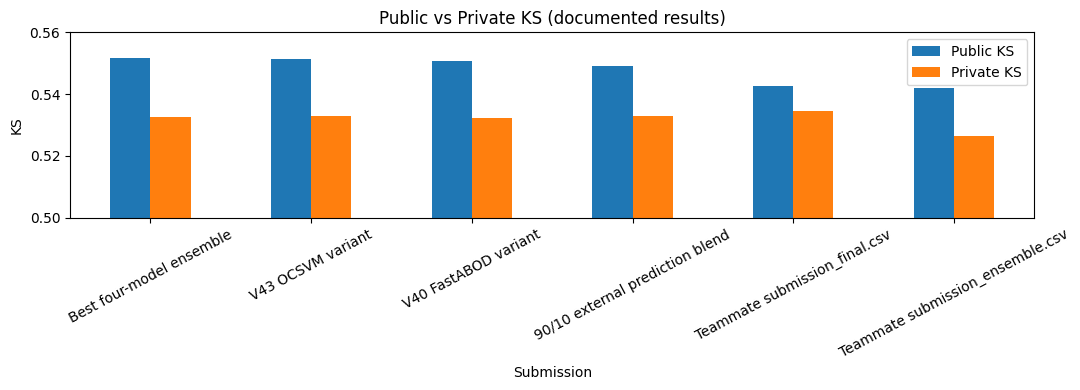

In [4]:
leaderboard = pd.DataFrame([
    ('Best four-model ensemble', .55163, .53271),
    ('V43 OCSVM variant', .55150, .53288),
    ('V40 FastABOD variant', .55080, .53243),
    ('90/10 external prediction blend', .54903, .53308),
    ('Teammate submission_final.csv', .54271, .53448),
    ('Teammate submission_ensemble.csv', .54182, .52654),
], columns=['Submission', 'Public KS', 'Private KS'])
leaderboard['Private − Public'] = leaderboard['Private KS'] - leaderboard['Public KS']
display(leaderboard.round(5)) if 'display' in globals() else print(leaderboard.round(5).to_string(index=False))

ax = leaderboard.set_index('Submission')[['Public KS', 'Private KS']].plot(
    kind='bar', figsize=(11,4), rot=28, title='Public vs Private KS (documented results)')
ax.set_ylabel('KS'); ax.set_ylim(0.50, 0.56); plt.tight_layout(); plt.show()

In [5]:
oof_summary = pd.DataFrame([
    ('Four-model ensemble baseline', 0.512201, 'Ensemble'),
    ('V40 FastABOD blend', 0.512757, 'Ensemble'),
    ('V41 COF blend', 0.512614, 'Ensemble'),
    ('V39 IsolationForest blend', 0.512475, 'Ensemble'),
    ('Original XGBoost V1', 0.508591, 'Single model'),
    ('V43 OCSVM XGBoost', 0.509916, 'Single model'),
],columns=['Method','OOF KS','Evaluation scope'])
print(oof_summary.to_string(index=False))
print('Best documented aligned ensemble OOF AUC:', 0.837744)
print('The two evaluation scopes must NOT be directly compared as ensemble improvements.')

                      Method   OOF KS Evaluation scope
Four-model ensemble baseline 0.512201         Ensemble
          V40 FastABOD blend 0.512757         Ensemble
               V41 COF blend 0.512614         Ensemble
   V39 IsolationForest blend 0.512475         Ensemble
         Original XGBoost V1 0.508591     Single model
           V43 OCSVM XGBoost 0.509916     Single model
Best documented aligned ensemble OOF AUC: 0.837744
The two evaluation scopes must NOT be directly compared as ensemble improvements.


## 9. Optional submission and artifact integrity checks
Only execute when the actual submission file has been attached. This check does not manufacture a Kaggle prediction or silently use the leaderboard values as predictions. It verifies shape and schema, not the model-training provenance.

In [6]:
from pathlib import Path

# To validate a submitted CSV in Kaggle, add it as a dataset and set the explicit path below.
SUBMISSION_CSV = None  # e.g. '/kaggle/input/my-submission/submission_best_055163.csv'

if SUBMISSION_CSV is None:
    print('CSV validation skipped — supply the original CSV path to enable it.')
else:
    check = pd.read_csv(SUBMISSION_CSV)
    assert check.columns.tolist() == ['application_id', 'default_probability']
    assert len(check) == 30000
    assert check['application_id'].is_unique
    assert check['default_probability'].notna().all()
    assert check['default_probability'].between(0,1).all()
    print('Submission schema valid:', SUBMISSION_CSV)

CSV validation skipped — supply the original CSV path to enable it.


## 10. Key takeaways & next steps

1. **Ensemble diversity matters:** standalone model gains do not guarantee ensemble gains.
2. **Temporal leakage control matters:** aggregate only data available before the applicant's decision cutoff.
3. **OOF consistency matters:** V40's small overall OOF improvement appeared in only 1/5 folds.
4. **Generalization matters:** all documented private scores were lower than public scores.
5. **Reproducibility requires data and trained artifacts:** full reconstruction needs the original competition tables, code for all four model training paths, feature tables, and fold alignment.

**Transparency:** This technical portfolio preserves substantive source code and reproduces self-contained evaluations, but it is not the verified end-to-end training notebook. Archived cells are guarded to keep Kaggle `Run All` usable without personal Drive access. No private label data, secret credentials or downloadable model weights are included.